# Bellows-Induced Biofilm Deformation

## 1. Modelling Substrate Stretching

### Physical motivation

Our previous structural FEM model investigated the response of an irregular biofilm to externally applied surface traction.

However, biofilm attached to the ISS wastewater tank's metallic bellows may also experience mechanical loading when the underlying substrate deforms.

We therefore introduce a prescribed substrate displacement to investigate how mechanical deformation is transmitted into the biofilm.

### Governing equations

We retain the static equilibrium equation:

$$
\nabla\cdot\boldsymbol{\sigma}=\mathbf{0}
$$

with the linear-elastic constitutive relationship:

$$
\boldsymbol{\sigma}=\mathbf{D}\boldsymbol{\varepsilon}
$$

### Prescribed substrate displacement

Instead of fixing the substrate:

$$
\mathbf{u}(x,0)=\mathbf{0}
$$

we prescribe horizontal displacement:

$$
\boxed{
u_x(x,0)=\varepsilon_b(x-x_0)
}
$$

$$
\boxed{
u_y(x,0)=0
}
$$

where:

- $\varepsilon_b$ is the prescribed substrate strain.
- $x_0$ is the stationary reference position.
- $x$ is the horizontal coordinate.

For our initial experiment:

$$
\varepsilon_b=0.001
$$

This corresponds to 0.1% substrate extension.

With a substrate length of $500\ \mu\mathrm{m}$ and reference position at its midpoint:

$$
x_0=250\ \mu\mathrm{m}
$$

The expected endpoint displacements are:

$$
u_x(0,0)=-0.25\ \mu\mathrm{m}
$$

$$
u_x(500,0)=+0.25\ \mu\mathrm{m}
$$

### Assumptions

We assume homogeneous, isotropic, small-strain linear elasticity, perfect biofilm–substrate adhesion, and quasi-static deformation.

External fluid traction is set to zero to isolate substrate-induced stresses.

This model does not yet simulate actual bellows folding, scraping, or contact mechanics.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.stochastic_geometry import random_height_profile
from src.structural_fem import solve_biofilm

# Geometry in micrometres
L = 500.0
x = np.linspace(0, L, 501)

h = random_height_profile(
    x,
    mean_height=80.0,
    roughness=15.0,
    n_features=10,
    min_height=5.0,
    rng=np.random.default_rng(0),
)

install jax and jaxlib to use terms_jax.py!
sfepy: WARNING: module /Users/zewei/miniconda3/envs/biofilm-fem/lib/python3.13/site-packages/sfepy/terms/terms_jax.py cannot be imported!
sfepy: reason:
 No module named 'jax'


## 2. Solving the Substrate-Deformation Problem

We impose a uniform substrate strain:

$$
\varepsilon_b=0.001
$$

The corresponding prescribed horizontal displacement is:

$$
u_x(x,0)=0.001(x-250\ \mu\mathrm{m})
$$

The upper biofilm surface and lateral boundaries are traction-free.

The structural FEM solver calculates the displacement field satisfying the prescribed substrate motion and elastic equilibrium.

We retain:

$$
E=64\ \mathrm{Pa}
$$

$$
\nu=0.3
$$

Both values are illustrative material parameters.

We set the external traction to zero:

$$
\mathbf{t}=\mathbf{0}
$$

This isolates the mechanical stresses generated by substrate deformation.

In [2]:
EPS_B = 0.001

result = solve_biofilm(
    x=x,
    h=h,
    ny=60,
    E=64.0,
    nu=0.3,
    traction_x=0.0,
    traction_y=0.0,
    substrate_strain=EPS_B,
)

print("=== Substrate Stretching Results ===")

print(
    f"Maximum displacement: "
    f"{result['max_displacement_um']:.6f} μm"
)

print(
    f"Maximum principal strain: "
    f"{result['max_principal_strain'] * 100:.4f}%"
)

print(
    f"Global maximum stress: "
    f"{result['global_peak']:.6f} Pa"
)

print(
    f"Interior maximum stress: "
    f"{result['interior_peak']:.6f} Pa"
)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy:     traction
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 6.816625e-05 (rel: 1.000000e+00)
sfepy:   residual:    0.03 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 1.390812e-18 (rel: 2.040324e-14)
sfepy: solved in 1 steps in 0.27 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
=== Substrate Stretching Results ===
Max

## 3. Verifying the Prescribed Boundary Condition

Before interpreting the calculated stresses, we verify that the FEM solution satisfies the imposed substrate displacement.

The prescribed condition is:

$$
u_x(x,0)=\varepsilon_b(x-x_0)
$$

For $\varepsilon_b=0.001$ and $x_0=250\ \mu\mathrm{m}$:

$$
u_x(0,0)=-0.25\ \mu\mathrm{m}
$$

$$
u_x(500,0)=+0.25\ \mu\mathrm{m}
$$

The vertical displacement must remain zero:

$$
u_y(x,0)=0
$$

We compare the numerical displacement at every substrate node against these analytical values.

The maximum absolute error is:

$$
\boxed{
e_{\max}=
\max_i
\left|
u_{x,i}^{\mathrm{FEM}}
-
u_{x,i}^{\mathrm{prescribed}}
\right|
}
$$

A sufficiently small error confirms that the displacement boundary condition has been applied correctly.

In [3]:
# Mesh coordinates (μm)
points = result["points_um"]

# FEM displacement converted from metres to μm
displacement_um = result["displacement"] / 1e-6

# Substrate nodes
base_nodes = result["boundaries"]["base"]

x_base = points[base_nodes, 0]

ux_base = displacement_um[base_nodes, 0]
uy_base = displacement_um[base_nodes, 1]

# Expected displacement (μm)
expected_ux = EPS_B * (x_base - L / 2)

# Calculate errors
error_x = np.max(np.abs(ux_base - expected_ux))
error_y = np.max(np.abs(uy_base))

print(f"Maximum horizontal BC error: {error_x:.6e} μm")
print(f"Maximum vertical BC error:   {error_y:.6e} μm")

print(f"Left-end displacement:  {ux_base[0]:.6f} μm")
print(f"Right-end displacement: {ux_base[-1]:.6f} μm")

# Automated verification
assert np.allclose(ux_base, expected_ux, atol=1e-8)
assert np.allclose(uy_base, 0.0, atol=1e-8)

print("Substrate displacement verification passed.")

Maximum horizontal BC error: 5.551115e-17 μm
Maximum vertical BC error:   0.000000e+00 μm
Left-end displacement:  -0.250000 μm
Right-end displacement: 0.250000 μm
Substrate displacement verification passed.


## 4. Visualizing Bellows-Induced Displacement

The substrate stretching produces a displacement field throughout the attached biofilm.

We visualize the horizontal displacement component:

$$
u_x(x,y)
$$

Unlike displacement magnitude, horizontal displacement retains its sign.

Negative values indicate movement toward the left, while positive values indicate movement toward the right.

This allows us to distinguish the stretching behaviour on opposite sides of the substrate.

The resulting displacement field illustrates how imposed substrate motion is transmitted through the biofilm under the assumption of perfect adhesion.

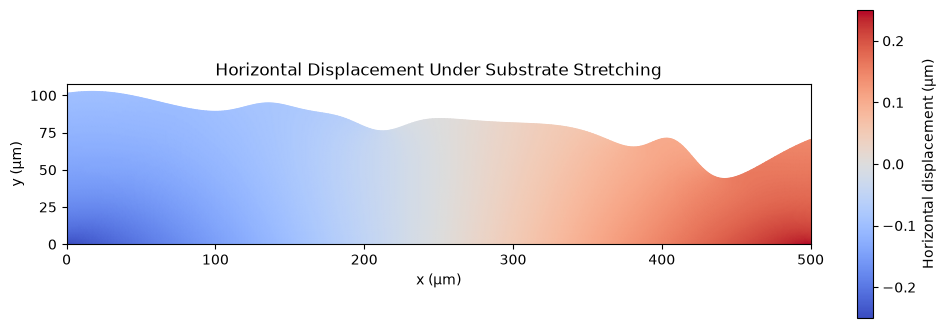

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))

plot = ax.tripcolor(
    points[:, 0],
    points[:, 1],
    result["triangles"],
    displacement_um[:, 0],
    shading="gouraud",
    cmap="coolwarm"
)

fig.colorbar(
    plot,
    ax=ax,
    label="Horizontal displacement (μm)"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Horizontal Displacement Under Substrate Stretching")

ax.set_aspect("equal")
ax.set_xlim(0, L)
ax.set_ylim(bottom=0)

plt.show()

## 5. Comparing Substrate Stretching and Compression

The metallic bellows of the ISS wastewater tank expand and contract during operation. Biofilm attached to the bellows may therefore experience alternating tensile and compressive deformation.

To investigate these effects, we prescribe:

$$
u_x(x,0)=\varepsilon_b(x-x_0)
$$

where the sign of $\varepsilon_b$ determines the deformation mode.

### Stretching

For $\varepsilon_b>0$, the substrate extends horizontally.

The imposed deformation produces tensile strain along the substrate:

$$
\varepsilon_{xx}=\frac{\partial u_x}{\partial x}
=\varepsilon_b>0
$$

### Compression

For $\varepsilon_b<0$, the substrate contracts horizontally:

$$
\varepsilon_{xx}=\varepsilon_b<0
$$

The resulting deformation produces compressive strain along the substrate.

### Linear-elastic symmetry

Under linear elasticity, reversing the prescribed displacement while keeping all other loading conditions unchanged should reverse the signs of the displacement and stress components:

$$
\mathbf{u}_{-\varepsilon_b}
=
-\mathbf{u}_{+\varepsilon_b}
$$

$$
\boldsymbol{\sigma}_{-\varepsilon_b}
=
-\boldsymbol{\sigma}_{+\varepsilon_b}
$$

However, von Mises equivalent stress is insensitive to the sign reversal:

$$
\boxed{
\sigma_e(-\varepsilon_b)=\sigma_e(+\varepsilon_b)
}
$$

Therefore, we expect stretching and compression of equal magnitude to produce identical von Mises stress distributions.

This symmetry is a useful numerical verification of our linear-elastic implementation.

**Limitation:** Actual biofilms may behave differently under tension and compression due to nonlinear material behaviour, buckling, adhesion loss, and fracture. These mechanisms are not included in the current model.

In [5]:
# Substrate strain scenarios
strain_scenarios = {
    "stretching": 0.001,
    "compression": -0.001,
    "stationary": 0.0,
}

bellows_results = {}

for name, eps_b in strain_scenarios.items():

    r = solve_biofilm(
        x=x,
        h=h,
        ny=60,
        E=64.0,
        nu=0.3,
        traction_x=0.0,
        traction_y=0.0,
        substrate_strain=eps_b,
    )

    bellows_results[name] = r

    print(
        f"{name:12s} | "
        f"Max displacement = {r['max_displacement_um']:.6f} μm | "
        f"Interior stress = {r['interior_peak']:.6f} Pa"
    )

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 6.816625e-05 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 1.390812e-18 (rel: 2.040324e-14)
sfepy: solved in 1 steps in 0.26 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
stretching   | Max displacement = 0.2500

## 6. Verifying Linear-Elastic Symmetry

For a linear-elastic material subjected to prescribed substrate displacement, the equilibrium problem is linear.

When the prescribed displacement is reversed:

$$
\mathbf{u}_{-}=-\mathbf{u}_{+}
$$

The corresponding stress tensor also reverses:

$$
\boldsymbol{\sigma}_{-}=-\boldsymbol{\sigma}_{+}
$$

However, von Mises equivalent stress remains unchanged because it depends on squared differences between stress components.

We verify these relationships numerically by comparing the stretching and compression solutions.

Agreement provides an additional verification of the FEM implementation.

In [6]:
stretch = bellows_results["stretching"]
compress = bellows_results["compression"]
stationary = bellows_results["stationary"]

# Displacement symmetry
displacement_error = np.max(
    np.abs(
        stretch["displacement"]
        + compress["displacement"]
    )
)

# Stress tensor symmetry
stress_error = np.max(
    np.abs(
        stretch["stress"]
        + compress["stress"]
    )
)

# Von Mises symmetry
von_mises_error = np.max(
    np.abs(
        stretch["sigma_e"]
        - compress["sigma_e"]
    )
)

# Stationary reference
stationary_displacement = np.max(
    np.abs(stationary["displacement"])
)

stationary_stress = np.max(
    np.abs(stationary["sigma_e"])
)

assert np.allclose(
    stretch["displacement"],
    -compress["displacement"],
    atol=1e-12
)

assert np.allclose(
    stretch["stress"],
    -compress["stress"],
    atol=1e-8
)

assert np.allclose(
    stretch["sigma_e"],
    compress["sigma_e"],
    atol=1e-8
)

assert np.allclose(
    stationary["displacement"],
    0.0,
    atol=1e-12
)

assert np.allclose(
    stationary["sigma_e"],
    0.0,
    atol=1e-8
)

print("All symmetry checks passed.")

print("=== Linear-Elastic Symmetry Verification ===")

print(f"Displacement symmetry error: {displacement_error:.6e} m")
print(f"Stress symmetry error:       {stress_error:.6e} Pa")
print(f"Von Mises symmetry error:    {von_mises_error:.6e} Pa")

print(f"\nStationary displacement: {stationary_displacement:.6e} m")
print(f"Stationary stress:       {stationary_stress:.6e} Pa")

All symmetry checks passed.
=== Linear-Elastic Symmetry Verification ===
Displacement symmetry error: 0.000000e+00 m
Stress symmetry error:       0.000000e+00 Pa
Von Mises symmetry error:    0.000000e+00 Pa

Stationary displacement: 0.000000e+00 m
Stationary stress:       0.000000e+00 Pa


## 7. Visualizing Stretching and Compression

We compare the horizontal displacement fields produced by equal-magnitude substrate stretching and compression.

For stretching:

$$
\varepsilon_b=+0.001
$$

For compression:

$$
\varepsilon_b=-0.001
$$

The horizontal displacement is expected to reverse direction between the two scenarios.

However, the magnitude of deformation should remain unchanged.

We use a shared colour scale to ensure that the two displacement fields can be compared directly.

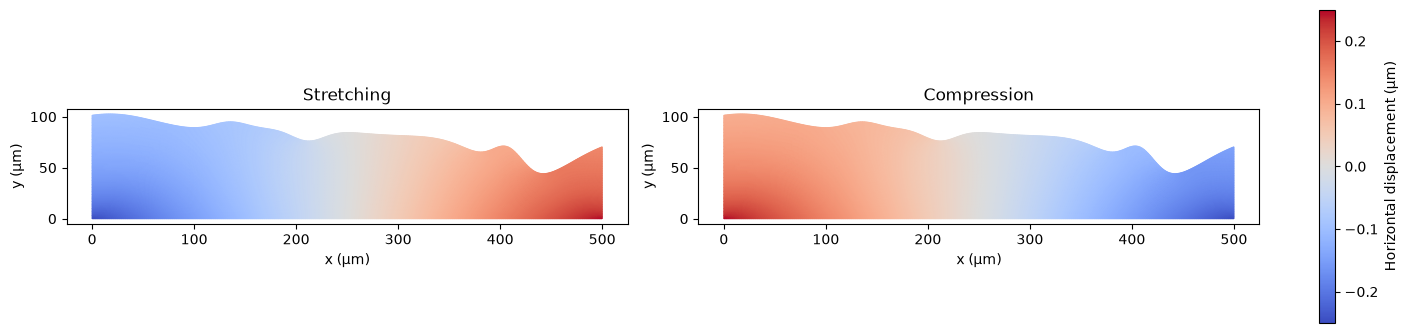

In [7]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4),
    constrained_layout=True
)

# Shared displacement scale
max_abs_ux = max(
    np.max(np.abs(r["displacement"][:, 0]))
    for r in [stretch, compress]
) / 1e-6

for ax, (name, r) in zip(
    axes,
    [
        ("Stretching", stretch),
        ("Compression", compress)
    ]
):

    points = r["points_um"]

    ux_um = r["displacement"][:, 0] / 1e-6

    plot = ax.tripcolor(
        points[:, 0],
        points[:, 1],
        r["triangles"],
        ux_um,
        shading="gouraud",
        cmap="coolwarm",
        vmin=-max_abs_ux,
        vmax=max_abs_ux
    )

    ax.set_title(name)
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    ax.set_aspect("equal")

fig.colorbar(
    plot,
    ax=axes,
    label="Horizontal displacement (μm)",
    shrink=0.8
)

plt.show()

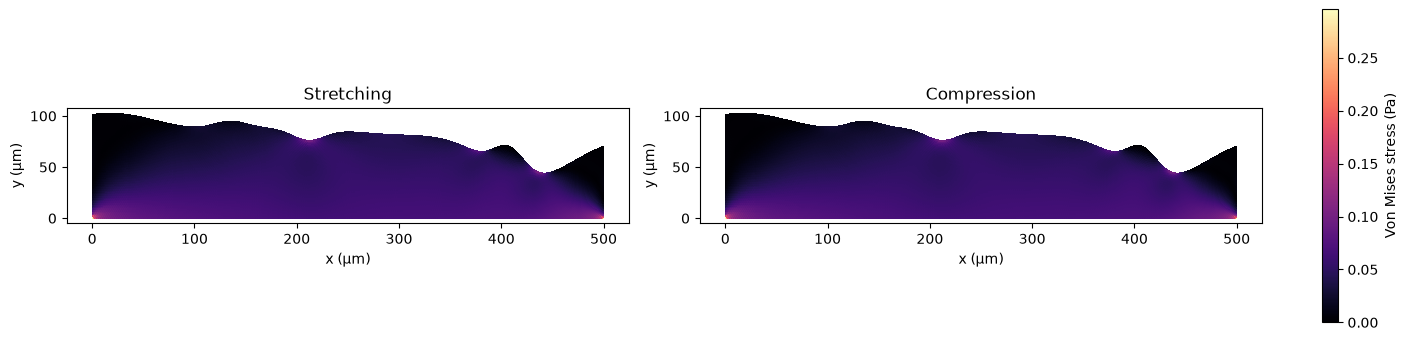

In [8]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4),
    constrained_layout=True
)

vmax = max(
    stretch["sigma_e"].max(),
    compress["sigma_e"].max()
)

for ax, (name, r) in zip(
    axes,
    [
        ("Stretching", stretch),
        ("Compression", compress)
    ]
):

    points = r["points_um"]

    plot = ax.tripcolor(
        points[:, 0],
        points[:, 1],
        r["triangles"],
        facecolors=r["sigma_e"],
        shading="flat",
        cmap="magma",
        vmin=0,
        vmax=vmax
    )

    ax.set_title(name)
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    ax.set_aspect("equal")

fig.colorbar(
    plot,
    ax=axes,
    label="Von Mises stress (Pa)",
    shrink=0.8
)

plt.show()

## 8. Modelling Nonuniform Substrate Deformation

Our previous simulations assumed uniform substrate stretching or compression.

However, the metallic bellows contain repeated convolutions that deform nonuniformly during expansion and contraction.

To investigate how nonuniform substrate movement affects biofilm stresses, we introduce a sinusoidal displacement boundary condition:

$$
\boxed{
u_x(x,0)=A\sin\left(\frac{2\pi(x-x_{\min})}{\lambda}\right)
}
$$

$$
u_y(x,0)=0
$$

where:

- $A$ is the maximum horizontal displacement amplitude.
- $\lambda$ is the spatial wavelength.
- $x_{\min}$ is the left endpoint of the substrate.

The corresponding imposed horizontal strain is:

$$
\boxed{
\varepsilon_{xx}(x,0)
=
\frac{\partial u_x}{\partial x}
=
\frac{2\pi A}{\lambda}
\cos\left(\frac{2\pi(x-x_{\min})}{\lambda}\right)
}
$$

Unlike uniform stretching, the substrate strain now varies with position.

Regions of positive strain undergo local extension, while regions of negative strain undergo local compression.

For our initial simulation:

$$
A=0.25\ \mu\mathrm m,\qquad
\lambda=250\ \mu\mathrm m
$$

The maximum imposed substrate strain magnitude is:

$$
|\varepsilon_{xx}|_{\max}
=
\frac{2\pi(0.25)}{250}
\approx0.00628
$$

This corresponds to approximately 0.628% strain.

The model remains quasi-static and linearly elastic. It does not yet account for actual bellows curvature, folding, or contact mechanics.

In [9]:
A = 0.25          # μm
WAVELENGTH = 250  # μm

sinusoidal_result = solve_biofilm(
    x=x,
    h=h,
    ny=60,
    E=64.0,
    nu=0.3,
    traction_x=0.0,
    traction_y=0.0,
    substrate_mode="sinusoidal",
    substrate_amplitude=A,
    substrate_wavelength=WAVELENGTH,
)

print("Maximum displacement:",
      sinusoidal_result["max_displacement_um"], "μm")

print("Maximum principal strain:",
      sinusoidal_result["max_principal_strain"] * 100, "%")

print("Interior maximum stress:",
      sinusoidal_result["interior_peak"], "Pa")

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 8.162149e-05 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.21 [s]
sfepy: nls: iter: 1, residual: 1.056098e-18 (rel: 1.293898e-14)
sfepy: solved in 1 steps in 0.26 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
Maximum displacement: 0.2499802610509540

In [10]:
points = sinusoidal_result["points_um"]

base_nodes = sinusoidal_result["boundaries"]["base"]

x_base = points[base_nodes, 0]

ux_base = (
    sinusoidal_result["displacement"][base_nodes, 0]
    / 1e-6
)

expected_ux = A * np.sin(
    2 * np.pi * (x_base - x.min()) / WAVELENGTH
)

error = np.max(np.abs(ux_base - expected_ux))

print(f"Maximum boundary-condition error: {error:.6e} μm")

assert np.allclose(
    ux_base,
    expected_ux,
    atol=1e-8
)

print("Sinusoidal displacement verification passed.")

Maximum boundary-condition error: 8.881784e-16 μm
Sinusoidal displacement verification passed.


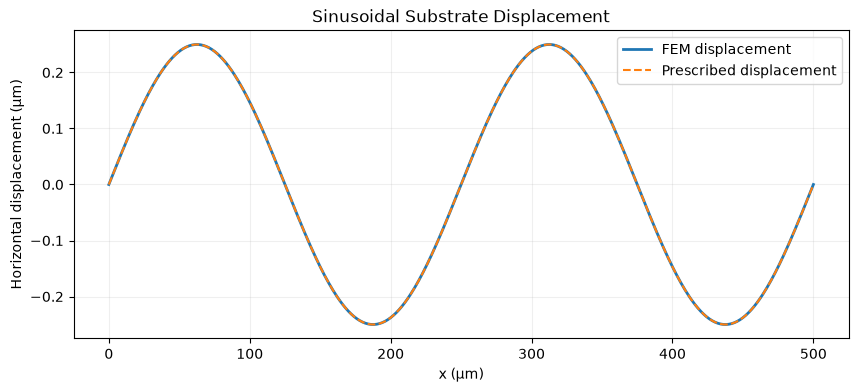

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    x_base,
    ux_base,
    label="FEM displacement",
    linewidth=2
)

ax.plot(
    x_base,
    expected_ux,
    "--",
    label="Prescribed displacement"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("Horizontal displacement (μm)")
ax.set_title("Sinusoidal Substrate Displacement")

ax.legend()
ax.grid(alpha=0.2)

plt.show()

## 9. Verifying Linear Scaling with Substrate Displacement

For linear elasticity, the equilibrium equations are linear in displacement.

If the prescribed substrate displacement is multiplied by a constant
factor $k$, the resulting displacement, strain, and stress fields
should scale by the same factor:

$$
\mathbf{u}(kA)=k\mathbf{u}(A)
$$

$$
\boldsymbol{\varepsilon}(kA)
=k\boldsymbol{\varepsilon}(A)
$$

$$
\boldsymbol{\sigma}(kA)
=k\boldsymbol{\sigma}(A)
$$

Consequently, the von Mises equivalent stress satisfies:

$$
\sigma_e(kA)=|k|\sigma_e(A)
$$

We verify this relationship by varying the prescribed displacement
amplitude while keeping the biofilm geometry, material properties,
and wavelength constant.

This provides an additional numerical verification of our
linear-elastic implementation.

In [12]:
amplitudes = [0.025, 0.05, 0.10, 0.25]

amplitude_results = []

for A_test in amplitudes:

    r = solve_biofilm(
        x=x,
        h=h,
        ny=60,
        E=64.0,
        nu=0.3,
        traction_x=0.0,
        traction_y=0.0,
        substrate_mode="sinusoidal",
        substrate_amplitude=A_test,
        substrate_wavelength=250.0,
    )

    amplitude_results.append({
        "amplitude": A_test,
        "max_strain": r["max_principal_strain"],
        "interior_stress": r["interior_peak"],
    })

    print(
        f"A={A_test:.3f} μm | "
        f"Max strain={r['max_principal_strain'] * 100:.4f}% | "
        f"Interior stress={r['interior_peak']:.6f} Pa"
    )

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (60120, 60120)
sfepy: assembling matrix graph...
sfepy: ...done in 0.02 s
sfepy: matrix structural nonzeros: 832712 (2.30e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     traction
sfepy:     biofilm
sfepy: ...done in 0.01 s
sfepy: nls: iter: 0, residual: 8.162149e-06 (rel: 1.000000e+00)
sfepy:   residual:    0.02 [s]
sfepy:     matrix:    0.01 [s]
sfepy:      solve:    0.22 [s]
sfepy: nls: iter: 1, residual: 1.058527e-19 (rel: 1.296873e-14)
sfepy: solved in 1 steps in 0.26 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
A=0.025 μm | Max strain=0.1295% | Interi

## 10. Modelling a Rounded Bellows Convolution

### Engineering assumptions

We approximate one convolution of the metallic bellows as two straight segments connected by a circular arc.

This geometry is intended to capture two mechanical behaviours:

1. Rotation of the approximately straight metal segments.
2. Bending concentrated near the rounded fold.

The geometry is characterized by:

- $l$: Length of each straight segment.
- $\theta$: Opening angle between the segments.
- $R$: Radius of curvature at the apex.

The rounded apex replaces the sharp corner of our previous V-shaped model.

### Curvature

For a circular arc, curvature is:

$$
\boxed{\kappa=\frac{1}{R}}
$$

The straight segments have zero curvature:

$$
\kappa_{\mathrm{straight}}=0
$$

The rounded apex has constant curvature:

$$
\kappa_{\mathrm{apex}}=\frac{1}{R}
$$

The circular arc is constructed to be tangent to both straight segments, ensuring that the surface has a continuous tangent direction.

However, curvature changes discontinuously where the straight segments meet the circular arc.

### Mechanical interpretation

As the bellows opens or closes, its fold geometry changes.

The resulting movement may produce bending-induced strain in the attached biofilm.

A simplified relationship is:

$$
\varepsilon_{\mathrm{bend}}\approx z\Delta\kappa
$$

where $z$ represents distance from an appropriate neutral reference surface.

This motivates investigating whether biofilm thickness influences the magnitude of bending-induced strain.

**Important:** The geometry and deformation parameters are illustrative. The model does not yet describe the actual constitutive mechanics of the metallic bellows.

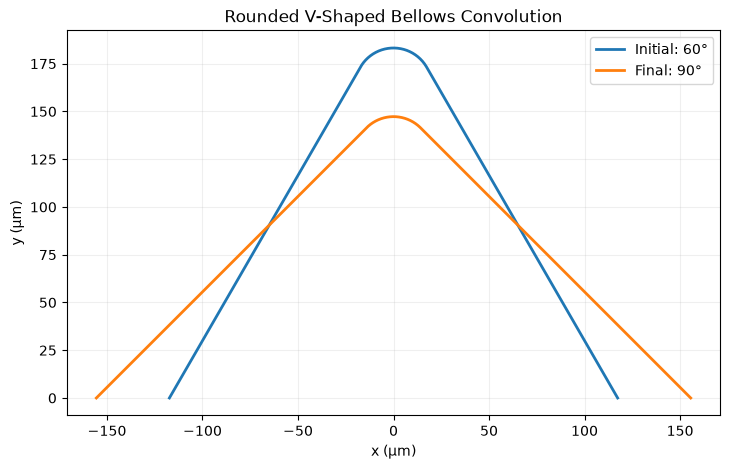

In [13]:
from src.rounded_bellows import rounded_bellows_profile

SEGMENT_LENGTH = 200.0  # μm
RADIUS = 20.0           # μm

THETA_INITIAL = 60.0
THETA_FINAL = 90.0

points_initial, s_initial = rounded_bellows_profile(
    segment_length=SEGMENT_LENGTH,
    angle_deg=THETA_INITIAL,
    radius=RADIUS,
)

points_final, s_final = rounded_bellows_profile(
    segment_length=SEGMENT_LENGTH,
    angle_deg=THETA_FINAL,
    radius=RADIUS,
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    points_initial[:, 0],
    points_initial[:, 1],
    label="Initial: 60°",
    linewidth=2,
)

ax.plot(
    points_final[:, 0],
    points_final[:, 1],
    label="Final: 90°",
    linewidth=2,
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Rounded V-Shaped Bellows Convolution")

ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

In [14]:
def inspect_bellows(points, s):
    segment_lengths = np.linalg.norm(
        np.diff(points, axis=0),
        axis=1,
    )

    print(f"Number of points: {len(points)}")
    print(f"Total arc length: {s[-1]:.3f} μm")
    print(f"Minimum segment length: {segment_lengths.min():.4f} μm")
    print(f"Maximum segment length: {segment_lengths.max():.4f} μm")
    print(f"Width: {np.ptp(points[:, 0]):.3f} μm")
    print(f"Height: {np.ptp(points[:, 1]):.3f} μm")


print("=== Initial geometry ===")
inspect_bellows(points_initial, s_initial)

print("\n=== Final geometry ===")
inspect_bellows(points_final, s_final)

=== Initial geometry ===
Number of points: 300
Total arc length: 441.887 μm
Minimum segment length: 0.4189 μm
Maximum segment length: 2.0202 μm
Width: 234.641 μm
Height: 183.205 μm

=== Final geometry ===
Number of points: 300
Total arc length: 431.416 μm
Minimum segment length: 0.3142 μm
Maximum segment length: 2.0202 μm
Width: 311.127 μm
Height: 147.279 μm


## 11. Constructing a Biofilm Layer on the Curved Bellows

Our previous biofilm model assumed a flat substrate. We now construct
a biofilm layer attached to the initial rounded bellows geometry.

### Curvilinear coordinates

We describe the biofilm using two coordinates:

- $s$: Arc-length coordinate along the bellows surface.
- $\eta$: Normalized coordinate through the biofilm thickness.

The position of a point within the biofilm is:

$$
\boxed{
\mathbf r(s,\eta)
=
\mathbf r_b(s)
+
\eta h(s)\mathbf n(s)
}
$$

where $\mathbf r_b(s)$ is the substrate position, $h(s)$ is the
local biofilm thickness, and $\mathbf n(s)$ is the unit surface normal.

The substrate and exposed surface correspond to:

$$
\mathbf r(s,0)=\mathbf r_b(s)
$$

$$
\mathbf r(s,1)=\mathbf r_b(s)+h(s)\mathbf n(s)
$$

### Surface normals

For a substrate parameterized by arc length:

$$
\mathbf r_b(s)=
\begin{bmatrix}
x(s)\\
y(s)
\end{bmatrix}
$$

the unit tangent is:

$$
\mathbf t(s)=\frac{d\mathbf r_b}{ds}
$$

A unit normal is obtained by rotating the tangent by 90°:

$$
\boxed{
\mathbf n(s)=
\begin{bmatrix}
-t_y(s)\\
t_x(s)
\end{bmatrix}
}
$$

The sign is chosen so that the normal points into the biofilm.

### Geometric validity

The normal-offset construction is valid only when the resulting
biofilm layer does not fold over or intersect itself.

In particular, the local thickness must be sufficiently small
relative to the substrate's radius of curvature on the offset side.

We will verify element orientation and mesh quality before
using the geometry for structural FEM.

In [15]:
from src.curved_layer_mesh import build_curved_layer_mesh

# Initial bellows geometry
substrate = points_initial

# Constant biofilm thickness
thickness = np.full(
    len(substrate),
    10.0
)

# Generate triangular mesh
biofilm_points, biofilm_triangles, biofilm_boundaries = (
    build_curved_layer_mesh(
        substrate,
        thickness,
        ny=20
    )
)

print("Nodes:", len(biofilm_points))
print("Triangles:", len(biofilm_triangles))

Nodes: 6300
Triangles: 11960


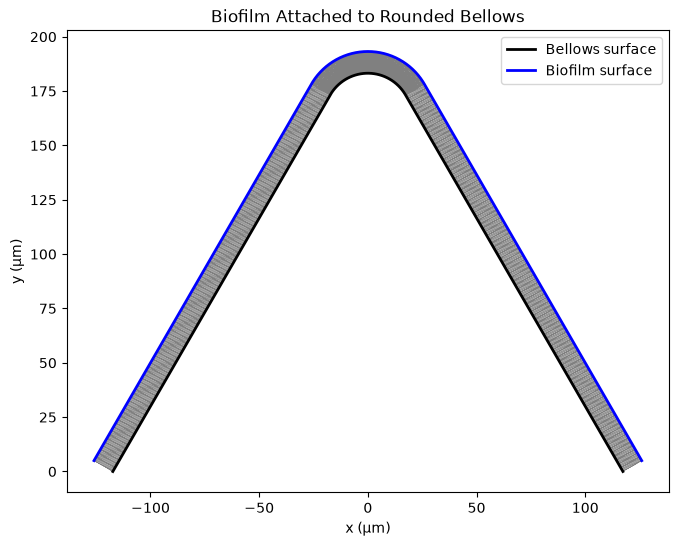

In [16]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.triplot(
    biofilm_points[:, 0],
    biofilm_points[:, 1],
    biofilm_triangles,
    color="gray",
    linewidth=0.3
)

# Substrate
base_nodes = biofilm_boundaries["substrate"]

ax.plot(
    biofilm_points[base_nodes, 0],
    biofilm_points[base_nodes, 1],
    color="black",
    linewidth=2,
    label="Bellows surface"
)

# Exposed biofilm surface
top_nodes = biofilm_boundaries["top"]

ax.plot(
    biofilm_points[top_nodes, 0],
    biofilm_points[top_nodes, 1],
    color="blue",
    linewidth=2,
    label="Biofilm surface"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Biofilm Attached to Rounded Bellows")

ax.set_aspect("equal")
ax.legend()

plt.show()

In [17]:
from src.rounded_bellows import deform_rounded_bellows

deformation = deform_rounded_bellows(
    segment_length=200.0,
    initial_angle_deg=60.0,
    final_angle_deg=90.0,
    initial_radius=20.0,
)

p0 = deformation["initial_points"]
p1 = deformation["final_points"]

s0 = deformation["s_initial"]
s1 = deformation["s_final"]

print("Initial radius:", deformation["radius_initial"])
print("Final radius:", deformation["radius_final"])

print("Initial arc length:", s0[-1])
print("Final arc length:", s1[-1])

print("Length difference:", s1[-1] - s0[-1])

Initial radius: 20.0
Final radius: 26.66666666666667
Initial arc length: 441.8871364649835
Final arc length: 441.8874714064603
Length difference: 0.000334941476808126


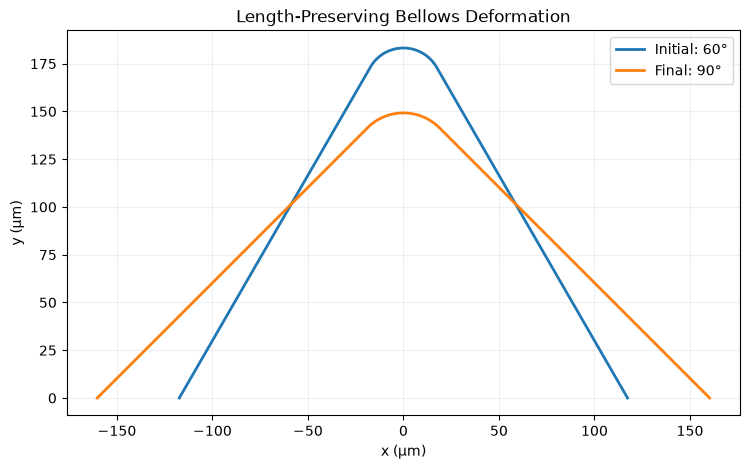

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    p0[:, 0],
    p0[:, 1],
    label="Initial: 60°",
    linewidth=2
)

ax.plot(
    p1[:, 0],
    p1[:, 1],
    label="Final: 90°",
    linewidth=2
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Length-Preserving Bellows Deformation")

ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

## 12. Generating Stochastic Biofilm Morphology on the Bellows

Our previous stochastic biofilm model generated irregular thickness
profiles over a flat substrate.

We now extend this approach to a curved bellows surface.

### Stochastic thickness profile

Biofilm thickness varies along the bellows surface:

$$
h=h(s)
$$

where $s$ represents the material arc-length coordinate.

We generate $h(s)$ using the same stochastic morphology generator
developed previously.

### Curved biofilm geometry

The biofilm occupies:

$$
\boxed{
\mathbf r(s,\eta)
=
\mathbf r_b(s)+\eta h(s)\mathbf n(s)
}
$$

where:

- $\mathbf r_b(s)$ is the bellows surface.
- $\mathbf n(s)$ is the unit normal pointing into the biofilm.
- $h(s)$ is the local biofilm thickness.
- $\eta\in[0,1]$ is the normalized thickness coordinate.

The bottom boundary corresponds to the biofilm–metal interface:

$$
\mathbf r(s,0)=\mathbf r_b(s)
$$

The exposed biofilm surface corresponds to:

$$
\mathbf r(s,1)=\mathbf r_b(s)+h(s)\mathbf n(s)
$$

We initially use a mean thickness of $10\ \mu\mathrm{m}$ and
roughness of $3\ \mu\mathrm{m}$.

These are illustrative parameters selected to test the geometry
and meshing procedure, not experimentally measured biofilm properties.

### Geometric limitations

Normal-offset surfaces can become invalid when the biofilm is too
thick relative to the substrate curvature or when opposite surfaces
intersect.

We must therefore verify mesh orientation, element quality, and
potential self-intersection before conducting FEM simulations.

In [19]:
from src.stochastic_geometry import random_height_profile
from src.curved_layer_mesh import build_curved_layer_mesh

# Initial bellows geometry from Step 111
substrate = deformation["initial_points"]
s = deformation["s_initial"]

# Generate stochastic thickness along material coordinate
h_random = random_height_profile(
    s,
    mean_height=10.0,
    roughness=3.0,
    n_features=10,
    min_height=2.0,
    rng=np.random.default_rng(42)
)

print(f"Mean thickness: {h_random.mean():.3f} μm")
print(f"Minimum thickness: {h_random.min():.3f} μm")
print(f"Maximum thickness: {h_random.max():.3f} μm")

Mean thickness: 10.388 μm
Minimum thickness: 5.032 μm
Maximum thickness: 15.531 μm


In [20]:
biofilm_points, biofilm_triangles, biofilm_boundaries = (
    build_curved_layer_mesh(
        substrate_points=substrate,
        thickness=h_random,
        ny=20
    )
)

print("Number of nodes:", len(biofilm_points))
print("Number of triangles:", len(biofilm_triangles))

Number of nodes: 6300
Number of triangles: 11960


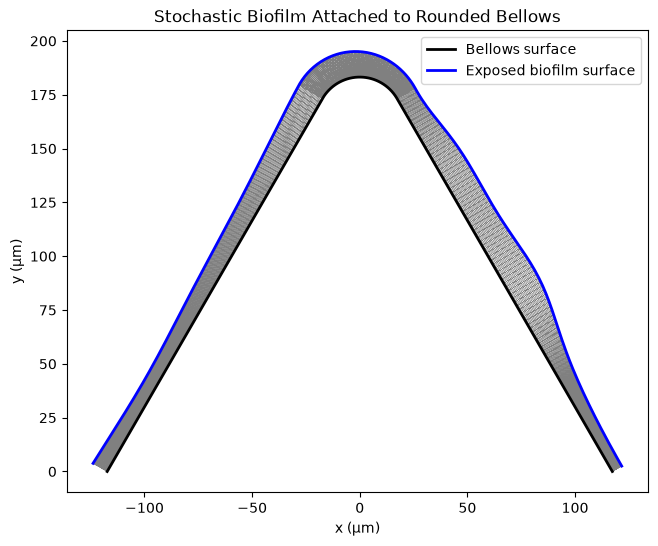

In [21]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.triplot(
    biofilm_points[:, 0],
    biofilm_points[:, 1],
    biofilm_triangles,
    linewidth=0.3,
    color="gray"
)

base_nodes = biofilm_boundaries["substrate"]
top_nodes = biofilm_boundaries["top"]

ax.plot(
    biofilm_points[base_nodes, 0],
    biofilm_points[base_nodes, 1],
    color="black",
    linewidth=2,
    label="Bellows surface"
)

ax.plot(
    biofilm_points[top_nodes, 0],
    biofilm_points[top_nodes, 1],
    color="blue",
    linewidth=2,
    label="Exposed biofilm surface"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Stochastic Biofilm Attached to Rounded Bellows")

ax.set_aspect("equal")
ax.legend()

plt.show()

## 13. Verifying Curved Biofilm Mesh Quality

Before solving the elasticity equations, we verify that the
triangular mesh represents a valid computational domain.

### Element orientation

For a triangle with vertices $\mathbf p_1$, $\mathbf p_2$,
and $\mathbf p_3$, its signed area is:

$$
A_e=
\frac12
\det
\begin{bmatrix}
x_2-x_1 & y_2-y_1\\
x_3-x_1 & y_3-y_1
\end{bmatrix}
$$

A positive signed area indicates counterclockwise orientation.

A zero area indicates a degenerate triangle.

### Element quality

We also calculate the minimum interior angle of each triangle.

Very small angles indicate narrow or distorted elements,
which can adversely affect FEM accuracy and numerical conditioning.

These checks are necessary but do not independently guarantee
that the mesh has no self-intersections.

In [22]:
P = biofilm_points[biofilm_triangles]

e01 = P[:, 1] - P[:, 0]
e02 = P[:, 2] - P[:, 0]
e12 = P[:, 2] - P[:, 1]

signed_areas = 0.5 * (
    e01[:, 0] * e02[:, 1]
    - e01[:, 1] * e02[:, 0]
)

def angle_between(a, b):
    dot = np.sum(a * b, axis=1)

    lengths = (
        np.linalg.norm(a, axis=1)
        * np.linalg.norm(b, axis=1)
    )

    cosine = np.clip(dot / lengths, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))

angles = np.column_stack([
    angle_between(e01, e02),
    angle_between(-e01, e12),
    angle_between(-e02, -e12)
])

print("=== Curved Mesh Quality ===")
print(f"Minimum signed area: {signed_areas.min():.6e} μm²")
print(f"Minimum triangle angle: {angles.min():.3f}°")
print(f"Inverted triangles: {np.sum(signed_areas <= 0)}")
print(f"Total mesh area: {signed_areas.sum():.3f} μm²")

=== Curved Mesh Quality ===
Minimum signed area: 1.016037e-01 μm²
Minimum triangle angle: 7.099°
Inverted triangles: 0
Total mesh area: 4559.261 μm²


## 14. Modelling the Interior Bellows Crevice

Our previous bellows geometry represented an inverted V-shaped fold.

We now reflect the geometry vertically to represent an upward-opening
V-shaped crevice.

The coordinate transformation is:

$$
\boxed{
x_{\mathrm{new}}=x_{\mathrm{old}}
}
$$

$$
\boxed{
y_{\mathrm{new}}=y_{\max}-y_{\mathrm{old}}
}
$$

This reflection preserves distances and arc lengths.

The resulting surface represents the interior-facing side of an
idealized bellows convolution.

Biofilm growth will be modelled along the surface normal pointing
into the crevice.

The geometry remains an engineering approximation rather than
a verified representation of the ISS wastewater tank.

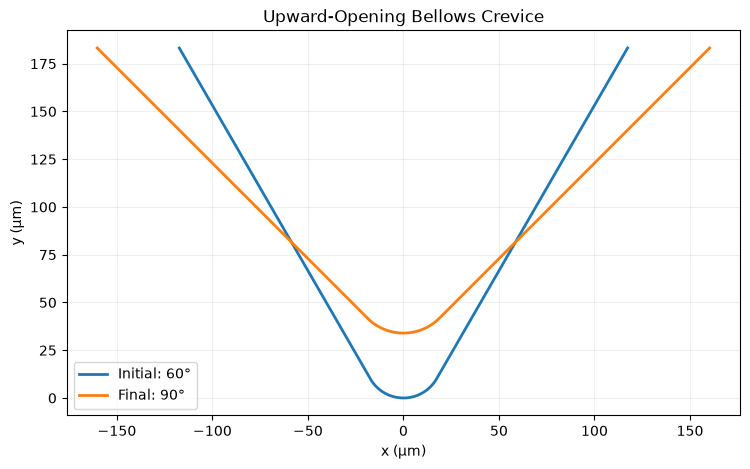

In [23]:
# Original length-preserving bellows geometries
p0 = deformation["initial_points"]
p1 = deformation["final_points"]

# Reflect both configurations using the SAME reference level
reflection_level = p0[:, 1].max()

crevice_initial = p0.copy()
crevice_final = p1.copy()

crevice_initial[:, 1] = reflection_level - p0[:, 1]
crevice_final[:, 1] = reflection_level - p1[:, 1]

# Translate both configurations together for convenient plotting
vertical_shift = min(
    crevice_initial[:, 1].min(),
    crevice_final[:, 1].min()
)

crevice_initial[:, 1] -= vertical_shift
crevice_final[:, 1] -= vertical_shift

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    crevice_initial[:, 0],
    crevice_initial[:, 1],
    label="Initial: 60°",
    linewidth=2
)

ax.plot(
    crevice_final[:, 0],
    crevice_final[:, 1],
    label="Final: 90°",
    linewidth=2
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Upward-Opening Bellows Crevice")

ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

## 15. Generating Biofilm Thickness Inside the Crevice

We describe the biofilm thickness using a stochastic function:

$$
h=h(s)
$$

where $s$ is the material coordinate along the bellows surface.

The biofilm grows normal to the metal surface, toward the interior
of the V-shaped crevice.

For the initial numerical experiment, we use:

$$
\overline h=10\ \mu\mathrm m
$$

with stochastic surface variations.

These parameters are illustrative and will later be varied
to investigate the effects of biofilm thickness and morphology.

The resulting geometry must be checked for self-intersection
before generating the FEM mesh.

In [24]:
from src.stochastic_geometry import random_height_profile

s = deformation["s_initial"]

h_crevice = random_height_profile(
    s,
    mean_height=10.0,
    roughness=3.0,
    n_features=10,
    min_height=2.0,
    rng=np.random.default_rng(42)
)

print(f"Mean thickness: {h_crevice.mean():.3f} μm")
print(f"Minimum thickness: {h_crevice.min():.3f} μm")
print(f"Maximum thickness: {h_crevice.max():.3f} μm")

Mean thickness: 10.388 μm
Minimum thickness: 5.032 μm
Maximum thickness: 15.531 μm


Nodes: 6300
Triangles: 11960


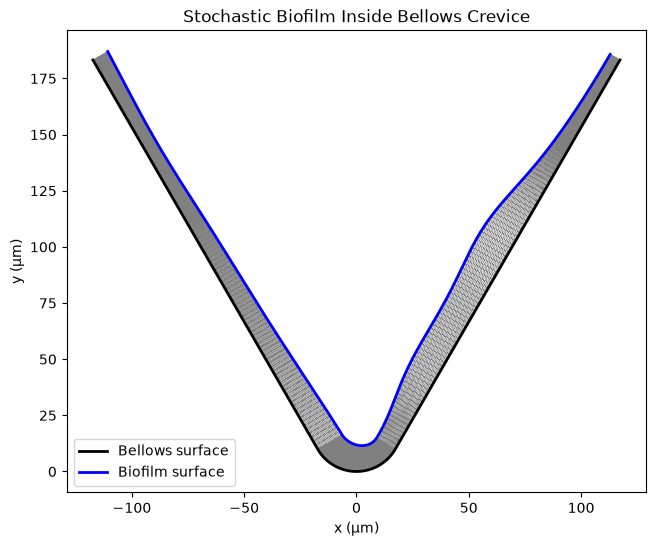

In [25]:
from src.curved_layer_mesh import build_curved_layer_mesh

biofilm_points, biofilm_triangles, biofilm_boundaries = (
    build_curved_layer_mesh(
        substrate_points=crevice_initial,
        thickness=h_crevice,
        ny=20,
        normal_side="left",
    )
)

print("Nodes:", len(biofilm_points))
print("Triangles:", len(biofilm_triangles))

fig, ax = plt.subplots(figsize=(9, 6))

ax.triplot(
    biofilm_points[:, 0],
    biofilm_points[:, 1],
    biofilm_triangles,
    linewidth=0.3,
    color="gray"
)

base_nodes = biofilm_boundaries["substrate"]
top_nodes = biofilm_boundaries["top"]

ax.plot(
    biofilm_points[base_nodes, 0],
    biofilm_points[base_nodes, 1],
    color="black",
    linewidth=2,
    label="Bellows surface"
)

ax.plot(
    biofilm_points[top_nodes, 0],
    biofilm_points[top_nodes, 1],
    color="blue",
    linewidth=2,
    label="Biofilm surface"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title("Stochastic Biofilm Inside Bellows Crevice")

ax.set_aspect("equal")
ax.legend()

plt.show()

## 16. Verifying the Curved Biofilm Mesh

Before solving the structural elasticity equations, we verify that
the generated mesh represents a valid biofilm domain.

### Local element validity

For each triangular element, the signed area is:

$$
A_e=\frac12
\begin{vmatrix}
x_2-x_1 & y_2-y_1\\
x_3-x_1 & y_3-y_1
\end{vmatrix}
$$

A zero signed area indicates a degenerate element.

We also calculate the minimum interior angle to identify highly
distorted triangles.

### Global geometric validity

A mesh may contain individually valid triangles while still
overlapping itself.

This is particularly important for biofilms growing inside a
V-shaped crevice, where opposing surfaces may approach one another.

We therefore check whether the exposed biofilm surface intersects
itself or the underlying bellows surface.

These checks establish geometric validity, not mechanical stability.

In [26]:
P = biofilm_points[biofilm_triangles]

e01 = P[:, 1] - P[:, 0]
e02 = P[:, 2] - P[:, 0]
e12 = P[:, 2] - P[:, 1]

signed_areas = 0.5 * (
    e01[:, 0] * e02[:, 1]
    - e01[:, 1] * e02[:, 0]
)

def angle_between(a, b):
    dot = np.sum(a * b, axis=1)

    lengths = (
        np.linalg.norm(a, axis=1)
        * np.linalg.norm(b, axis=1)
    )

    cosine = np.clip(dot / lengths, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))

angles = np.column_stack([
    angle_between(e01, e02),
    angle_between(-e01, e12),
    angle_between(-e02, -e12)
])

print("=== Curved Mesh Quality ===")
print(f"Minimum signed area: {signed_areas.min():.6e} μm²")
print(f"Minimum triangle angle: {angles.min():.3f}°")
print(f"Inverted triangles: {np.sum(signed_areas <= 0)}")
print(f"Total mesh area: {signed_areas.sum():.3f} μm²")

=== Curved Mesh Quality ===
Minimum signed area: 4.865124e-02 μm²
Minimum triangle angle: 7.099°
Inverted triangles: 0
Total mesh area: 4278.429 μm²


In [27]:
from shapely.geometry import LineString, Polygon

base_nodes = biofilm_boundaries["substrate"]
top_nodes = biofilm_boundaries["top"]

base_curve = biofilm_points[base_nodes]
top_curve = biofilm_points[top_nodes]

# Construct the complete biofilm boundary
boundary = np.vstack([
    base_curve,
    top_curve[::-1],
])

# Construct polygon
biofilm_polygon = Polygon(boundary)

# Check geometric validity
print("Polygon valid:", biofilm_polygon.is_valid)
print("Polygon area:", biofilm_polygon.area, "μm²")

# Check whether exposed surface intersects itself
top_line = LineString(top_curve)

print("Top surface simple:", top_line.is_simple)

# Check whether substrate intersects itself
base_line = LineString(base_curve)

print("Substrate simple:", base_line.is_simple)

Polygon valid: True
Polygon area: 4278.429242670624 μm²
Top surface simple: True
Substrate simple: True


In [28]:
from scipy.spatial.distance import cdist

# Pairwise distances between exposed-surface nodes
distances = cdist(top_curve, top_curve)

# Exclude nearby points along the same surface
indices = np.arange(len(top_curve))

index_separation = np.abs(
    indices[:, None] - indices[None, :]
)

# Exclude points fewer than 30 indices apart
distances[index_separation < 30] = np.inf

minimum_separation = np.min(distances)

print(
    f"Minimum nonlocal surface separation: "
    f"{minimum_separation:.3f} μm"
)

Minimum nonlocal surface separation: 4.617 μm


In [29]:
ny_values = [10, 20, 30, 40, 60]

for ny_test in ny_values:

    pts, tris, bounds = build_curved_layer_mesh(
        substrate_points=crevice_initial,
        thickness=h_crevice,
        ny=ny_test,
        normal_side="left",
    )

    P = pts[tris]

    e01 = P[:, 1] - P[:, 0]
    e02 = P[:, 2] - P[:, 0]
    e12 = P[:, 2] - P[:, 1]

    angles = np.column_stack([
        angle_between(e01, e02),
        angle_between(-e01, e12),
        angle_between(-e02, -e12),
    ])

    print(
        f"ny={ny_test:3d} | "
        f"Triangles={len(tris):6d} | "
        f"Minimum angle={angles.min():.2f}°"
    )

ny= 10 | Triangles=  5980 | Minimum angle=6.91°
ny= 20 | Triangles= 11960 | Minimum angle=7.10°
ny= 30 | Triangles= 17940 | Minimum angle=4.75°
ny= 40 | Triangles= 23920 | Minimum angle=3.56°
ny= 60 | Triangles= 35880 | Minimum angle=2.38°


In [30]:
from src.rounded_bellows import resample_bellows

# Common material-coordinate grid
N_SURFACE = 500

s_uniform = np.linspace(
    0,
    deformation["s_initial"][-1],
    N_SURFACE
)

# Resample initial and final configurations
p0_uniform = resample_bellows(
    deformation["initial_points"],
    deformation["s_initial"],
    s_uniform
)

p1_uniform = resample_bellows(
    deformation["final_points"],
    deformation["s_final"],
    s_uniform
)

# Reflect into upward-opening crevice
reflection_level = p0_uniform[:, 1].max()

crevice_initial_uniform = p0_uniform.copy()
crevice_final_uniform = p1_uniform.copy()

crevice_initial_uniform[:, 1] = (
    reflection_level - p0_uniform[:, 1]
)

crevice_final_uniform[:, 1] = (
    reflection_level - p1_uniform[:, 1]
)

# Common vertical translation
shift = min(
    crevice_initial_uniform[:, 1].min(),
    crevice_final_uniform[:, 1].min()
)

crevice_initial_uniform[:, 1] -= shift
crevice_final_uniform[:, 1] -= shift

ds = np.linalg.norm(
    np.diff(crevice_initial_uniform, axis=0),
    axis=1
)

print(f"Minimum spacing: {ds.min():.4f} μm")
print(f"Maximum spacing: {ds.max():.4f} μm")
print(f"Mean spacing:    {ds.mean():.4f} μm")

Minimum spacing: 0.8854 μm
Maximum spacing: 0.8855 μm
Mean spacing:    0.8855 μm


In [31]:
h_uniform = random_height_profile(
    s_uniform,
    mean_height=10.0,
    roughness=3.0,
    n_features=10,
    min_height=2.0,
    rng=np.random.default_rng(42)
)

In [32]:
ny_values = [10, 15, 20, 25, 30]

for ny_test in ny_values:

    pts, tris, bounds = build_curved_layer_mesh(
        substrate_points=crevice_initial_uniform,
        thickness=h_uniform,
        ny=ny_test,
        normal_side="left"
    )

    P = pts[tris]

    e01 = P[:, 1] - P[:, 0]
    e02 = P[:, 2] - P[:, 0]
    e12 = P[:, 2] - P[:, 1]

    angles = np.column_stack([
        angle_between(e01, e02),
        angle_between(-e01, e12),
        angle_between(-e02, -e12)
    ])

    print(
        f"ny={ny_test:3d} | "
        f"Triangles={len(tris):6d} | "
        f"Minimum angle={angles.min():.2f}°"
    )

ny= 10 | Triangles=  9980 | Minimum angle=14.10°
ny= 15 | Triangles= 14970 | Minimum angle=20.60°
ny= 20 | Triangles= 19960 | Minimum angle=15.86°
ny= 25 | Triangles= 24950 | Minimum angle=12.80°
ny= 30 | Triangles= 29940 | Minimum angle=10.72°


## 17. Final Curved Mesh Verification

The initial curved mesh exhibited narrow triangular elements due to
nonuniform sampling along the bellows surface.

We therefore resampled the bellows geometry using approximately
uniform arc-length intervals.

The resulting mesh achieved a minimum triangle angle of approximately
20.60° at 15 intervals through the biofilm thickness.

We now verify the final mesh geometry before proceeding to structural
FEM.

The checks include:

1. Positive element areas.
2. Consistency between mesh area and boundary polygon area.
3. Validity of the biofilm boundary polygon.
4. Absence of self-intersection along the exposed biofilm surface.

These checks provide preliminary geometric verification. They do not
independently establish that all interior triangles are nonoverlapping.

In [33]:
from shapely.geometry import Polygon, LineString

NY_CURVED = 15

curved_points, curved_triangles, curved_boundaries = (
    build_curved_layer_mesh(
        substrate_points=crevice_initial_uniform,
        thickness=h_uniform,
        ny=NY_CURVED,
        normal_side="left"
    )
)

# Calculate element areas
P = curved_points[curved_triangles]

AB = P[:, 1] - P[:, 0]
AC = P[:, 2] - P[:, 0]

signed_areas = 0.5 * (
    AB[:, 0] * AC[:, 1]
    - AB[:, 1] * AC[:, 0]
)

# Construct boundary polygon
base_curve = curved_points[
    curved_boundaries["substrate"]
]

top_curve = curved_points[
    curved_boundaries["top"]
]

boundary = np.vstack([
    base_curve,
    top_curve[::-1]
])

polygon = Polygon(boundary)

# Verification
print("=== Final Mesh Verification ===")

print("Nodes:", len(curved_points))
print("Triangles:", len(curved_triangles))

print("Minimum signed area:", signed_areas.min())
print("Inverted triangles:", np.sum(signed_areas <= 0))

print("Polygon valid:", polygon.is_valid)
print("Top surface simple:", LineString(top_curve).is_simple)

print("Mesh area:", signed_areas.sum())
print("Polygon area:", polygon.area)

relative_area_error = (
    abs(signed_areas.sum() - polygon.area)
    / polygon.area
)

print(f"Relative area error: {relative_area_error:.6e}")

assert np.all(signed_areas > 0)
assert polygon.is_valid
assert LineString(top_curve).is_simple
assert relative_area_error < 1e-6

print("Preliminary mesh verification passed.")

=== Final Mesh Verification ===
Nodes: 8000
Triangles: 14970
Minimum signed area: 0.1348047691811896
Inverted triangles: 0
Polygon valid: True
Top surface simple: True
Mesh area: 4278.331418753346
Polygon area: 4278.331418753344
Relative area error: 4.251633e-16
Preliminary mesh verification passed.


## 18. Structural FEM on a Curved Bellows Substrate

Our previous structural FEM simulations assumed a flat substrate.
We now extend the model to a biofilm attached to the curved interior
surface of a bellows convolution.

### Governing equations

Under quasi-static equilibrium:

$$
\nabla\cdot\boldsymbol{\sigma}=\mathbf 0
$$

For small-strain linear elasticity:

$$
\boldsymbol{\varepsilon}
=
\frac12\left(
\nabla\mathbf u+\nabla\mathbf u^T
\right)
$$

$$
\boldsymbol{\sigma}
=
\mathbf D\boldsymbol{\varepsilon}
$$

We retain the plane-strain approximation and homogeneous,
isotropic material properties.

### Prescribed bellows displacement

The biofilm is assumed perfectly attached to the bellows.

Consequently, the displacement of the biofilm–substrate interface
equals the displacement of the underlying metal surface:

$$
\boxed{
\mathbf u(s,0)
=
\mathbf r_1(s)-\mathbf r_0(s)
}
$$

Both displacement components are prescribed:

$$
u_x(s,0)=u_{b,x}(s)
$$

$$
u_y(s,0)=u_{b,y}(s)
$$

The exposed biofilm surface and lateral boundaries are initially
traction-free.

### Important limitations

The bellows deformation is prescribed geometrically rather than
calculated from the mechanical properties of the metal.

We also assume perfect biofilm adhesion, no fracture, no contact,
and no external fluid traction.

Because the solver uses small-strain linear elasticity, we initially
restrict bellows movement to small changes in opening angle.

Numerical verification is required before interpreting the resulting
stress field.

## 19. Verifying the Curved FEM Solver

Before applying bellows-induced displacement, we verify the curved
structural FEM solver using a zero-displacement reference case.

The substrate is fixed:

$$
\mathbf u(s,0)=\mathbf0
$$

All other boundaries are traction-free.

With no external loading, the expected equilibrium solution is:

$$
\boxed{
\mathbf u=\mathbf0
}
$$

$$
\boxed{
\boldsymbol{\sigma}=\mathbf0
}
$$

This test verifies that the curved mesh, boundary conditions,
elasticity equations, and postprocessing are compatible.

However, it does not yet verify the accuracy of nonzero
bellows-induced deformation.

from src.curved_structural_fem import solve_curved_biofilm

# Zero substrate displacement
zero_displacement = np.zeros(
    (len(curved_boundaries["substrate"]), 2)
)

zero_result = solve_curved_biofilm(
    points=curved_points,
    triangles=curved_triangles,
    boundaries=curved_boundaries,
    substrate_displacement=zero_displacement,
    E=64.0,
    nu=0.3,
)

print("=== Zero-Displacement Verification ===")

print(
    "Maximum displacement:",
    zero_result["max_displacement_um"],
    "μm"
)

print(
    "Maximum principal strain:",
    zero_result["max_principal_strain"]
)

print(
    "Maximum von Mises stress:",
    zero_result["global_peak"],
    "Pa"
)

assert np.allclose(
    zero_result["displacement"],
    0.0,
    atol=1e-12,
)

assert np.allclose(
    zero_result["sigma_e"],
    0.0,
    atol=1e-8,
)

print("Zero-displacement verification passed.")

## 22. Transferring Bellows Deformation into Structural FEM

### Objective

We now couple our geometric bellows model to the curved-biofilm
structural FEM solver.

The bellows is assumed to undergo a small change in opening angle:

$$
\theta_0=60^\circ,\qquad \theta_1=60.5^\circ
$$

### Material-point displacement

We track corresponding material points along the bellows surface.

The displacement of each point is:

$$
\boxed{
\mathbf u_b(s)=
\mathbf r(s,\theta_1)-\mathbf r(s,\theta_0)
}
$$

Both horizontal and vertical displacement components are prescribed
at the biofilm–substrate interface.

### Mechanical interpretation

The bellows deformation is transmitted into the attached biofilm
through the assumption of perfect adhesion.

The structural FEM then calculates the resulting displacement,
strain, and stress distributions.

The exposed biofilm surface remains traction-free.

### Limitations

The bellows deformation is prescribed geometrically rather than
calculated from the metal's mechanical properties.

We also assume small-strain linear elasticity, perfect adhesion,
and no fracture or contact.

A small change in opening angle is selected to reduce the effects
of finite rotation, although the validity of the approximation
must still be checked.

In [34]:
from src.rounded_bellows import (
    deform_rounded_bellows,
    resample_bellows,
)

# Bellows parameters
THETA_0 = 60.0
THETA_1 = 60.5

SEGMENT_LENGTH = 200.0
INITIAL_RADIUS = 20.0

# Generate length-preserving deformation
small_deformation = deform_rounded_bellows(
    segment_length=SEGMENT_LENGTH,
    initial_angle_deg=THETA_0,
    final_angle_deg=THETA_1,
    initial_radius=INITIAL_RADIUS,
)

# Use the SAME material coordinates as our biofilm mesh
p0 = resample_bellows(
    small_deformation["initial_points"],
    small_deformation["s_initial"],
    s_uniform,
)

p1 = resample_bellows(
    small_deformation["final_points"],
    small_deformation["s_final"],
    s_uniform,
)

# Reflect both configurations into an upward-opening V
reflection_level = p0[:, 1].max()

p0[:, 1] = reflection_level - p0[:, 1]
p1[:, 1] = reflection_level - p1[:, 1]

# Apply a common translation to both configurations
vertical_shift = min(p0[:, 1].min(), p1[:, 1].min())

p0[:, 1] -= vertical_shift
p1[:, 1] -= vertical_shift

# Calculate displacement of corresponding material points
bellows_displacement = p1 - p0

print("Maximum bellows displacement:",
      np.linalg.norm(bellows_displacement, axis=1).max(),
      "μm")

print("Maximum horizontal displacement:",
      np.max(np.abs(bellows_displacement[:, 0])),
      "μm")

print("Maximum vertical displacement:",
      np.max(np.abs(bellows_displacement[:, 1])),
      "μm")

substrate_nodes = curved_boundaries["substrate"]

mesh_substrate = curved_points[substrate_nodes]

geometry_error = np.max(
    np.linalg.norm(mesh_substrate - p0, axis=1)
)

print(
    f"Reference geometry mismatch: "
    f"{geometry_error:.6e} μm"
)

assert np.allclose(
    mesh_substrate,
    p0,
    atol=1e-8
)

print("Reference geometry verification passed.")

Maximum bellows displacement: 0.7832849274796843 μm
Maximum horizontal displacement: 0.7832849274796843 μm
Maximum vertical displacement: 0.47191276210764954 μm
Reference geometry mismatch: 0.000000e+00 μm
Reference geometry verification passed.


## 23. Solving Bellows-Induced Biofilm Deformation

We prescribe the calculated bellows displacement along the
biofilm–substrate interface:

$$
\mathbf u(s,0)=\mathbf u_b(s)
$$

The governing equation remains:

$$
\nabla\cdot\boldsymbol{\sigma}=\mathbf0
$$

with:

$$
\boldsymbol{\sigma}=\mathbf D\boldsymbol{\varepsilon}
$$

The solver calculates the elastic response of the biofilm to
the imposed bellows movement.

We initially retain the illustrative material properties:

$$
E=64\ \mathrm{Pa},\qquad \nu=0.3
$$

The resulting stresses describe the response of a perfectly
attached, linearly elastic biofilm to the prescribed deformation.

In [35]:
from src.curved_structural_fem import solve_curved_biofilm

bellows_result = solve_curved_biofilm(
    points=curved_points,
    triangles=curved_triangles,
    boundaries=curved_boundaries,
    substrate_displacement=bellows_displacement,
    E=64.0,
    nu=0.3,
)

print("=== Bellows-Induced FEM Results ===")

print(
    f"Maximum displacement: "
    f"{bellows_result['max_displacement_um']:.6f} μm"
)

print(
    f"Maximum principal strain: "
    f"{bellows_result['max_principal_strain'] * 100:.4f}%"
)

print(
    f"Maximum von Mises stress: "
    f"{bellows_result['global_peak']:.6f} Pa"
)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.332371e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.400313e-18 (rel: 2.552075e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
=== Bellows-Induced FEM Results ===
Maximum displacement: 0.

## 24. Verifying Bellows–Biofilm Displacement Coupling

Under perfect adhesion, the displacement of the biofilm at its
substrate interface must equal the displacement of the bellows.

Therefore:

$$
\boxed{
\mathbf u_{\mathrm{biofilm}}(s,0)
=
\mathbf u_{\mathrm{bellows}}(s)
}
$$

We calculate the maximum difference between the prescribed
bellows displacement and the FEM displacement at the substrate.

This verifies that the geometric deformation has been correctly
transferred into the structural model.

In [36]:
# FEM displacement at substrate nodes (μm)
fem_base_displacement = (
    bellows_result["displacement"][substrate_nodes] / 1e-6
)

# Compare against prescribed bellows displacement
bc_error = np.max(
    np.linalg.norm(
        fem_base_displacement - bellows_displacement,
        axis=1
    )
)

print(
    f"Maximum substrate displacement error: "
    f"{bc_error:.6e} μm"
)

assert np.allclose(
    fem_base_displacement,
    bellows_displacement,
    atol=1e-8
)

print("Bellows–biofilm coupling verification passed.")

Maximum substrate displacement error: 5.551115e-17 μm
Bellows–biofilm coupling verification passed.


## 25. Visualizing Bellows-Induced Stress

The bellows deformation generates internal stresses within
the attached biofilm.

We calculate the von Mises equivalent stress:

$$
\boxed{
\sigma_e=
\sqrt{
\frac12
\left[
(\sigma_{xx}-\sigma_{yy})^2+
(\sigma_{yy}-\sigma_{zz})^2+
(\sigma_{zz}-\sigma_{xx})^2
\right]
+3\tau_{xy}^2
}
}
$$

We visualize the element-averaged equivalent stress to identify
regions experiencing elevated mechanical loading.

Because the model assumes perfect adhesion and linear elasticity,
these stresses do not directly establish whether the biofilm
fractures or detaches.

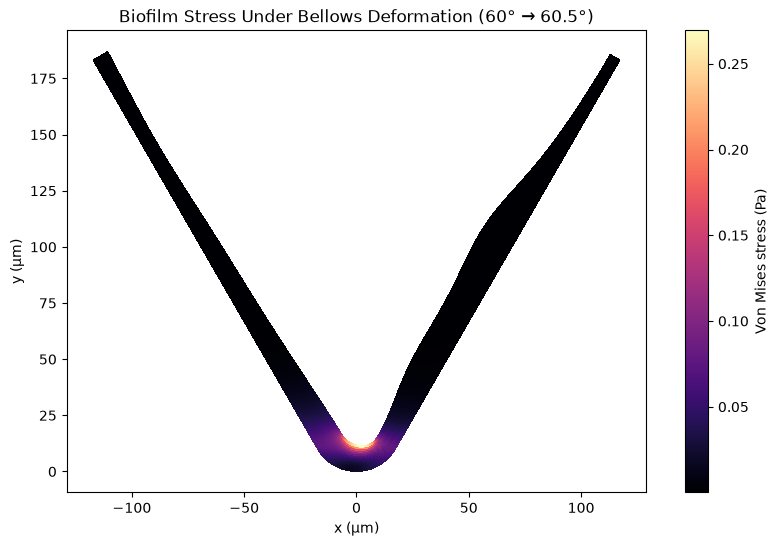

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))

plot = ax.tripcolor(
    bellows_result["points_um"][:, 0],
    bellows_result["points_um"][:, 1],
    bellows_result["triangles"],
    facecolors=bellows_result["sigma_e"],
    shading="flat",
    cmap="magma"
)

fig.colorbar(
    plot,
    ax=ax,
    label="Von Mises stress (Pa)"
)

ax.set_xlabel("x (μm)")
ax.set_ylabel("y (μm)")
ax.set_title(
    "Biofilm Stress Under Bellows Deformation "
    "(60° → 60.5°)"
)

ax.set_aspect("equal")

plt.show()

## 26. Verifying Rigid-Body Invariance

Before interpreting bellows-induced stresses, we verify that the
structural FEM distinguishes rigid-body movement from material
deformation.

### Rigid translation

Suppose the entire biofilm undergoes a uniform displacement:

$$
\mathbf u(x,y)=
\begin{bmatrix}
a\\b
\end{bmatrix}
$$

The displacement gradient is zero:

$$
\nabla\mathbf u=\mathbf0
$$

Therefore, the strain and stress tensors must also vanish:

$$
\boxed{
\boldsymbol{\varepsilon}=\mathbf0
}
$$

$$
\boxed{
\boldsymbol{\sigma}=\mathbf0
}
$$

We prescribe the same displacement at every substrate node.

Since the remaining boundaries are traction-free, the entire
biofilm should translate rigidly without developing internal stress.

This provides a numerical verification that the FEM does not
generate artificial stresses from uniform translation.

In [38]:
# Prescribed rigid translation (μm)
TRANSLATION_X = 0.5
TRANSLATION_Y = 0.3

n_base = len(curved_boundaries["substrate"])

translation = np.tile(
    [TRANSLATION_X, TRANSLATION_Y],
    (n_base, 1)
)

translation_result = solve_curved_biofilm(
    points=curved_points,
    triangles=curved_triangles,
    boundaries=curved_boundaries,
    substrate_displacement=translation,
    E=64.0,
    nu=0.3,
)

# Expected displacement at every mesh node (metres)
expected_translation = (
    np.array([TRANSLATION_X, TRANSLATION_Y]) * 1e-6
)

# Compare the entire FEM displacement field
translation_error = np.max(
    np.linalg.norm(
        translation_result["displacement"]
        - expected_translation,
        axis=1
    )
)

print("=== Rigid Translation Verification ===")

print(f"Maximum displacement error: {translation_error:.6e} m")
print(f"Maximum principal strain: {translation_result['max_principal_strain']:.6e}")
print(f"Maximum von Mises stress: {translation_result['global_peak']:.6e} Pa")

assert translation_error < 1e-10
assert translation_result["max_principal_strain"] < 1e-6
assert translation_result["global_peak"] < 1e-4

print("Rigid translation verification passed.")

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.415584e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.567046e-18 (rel: 2.519841e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
=== Rigid Translation Verification ===
Maximum displacement 

## 27. Verifying Infinitesimal Rigid-Body Rotation

The straight sections of our simplified bellows rotate during
expansion and contraction.

A rigidly rotating biofilm should not develop internal strain
solely because its position and orientation change.

For a small rotation $\omega$ about $(x_0,y_0)$:

$$
u_x=-\omega(y-y_0)
$$

$$
u_y=\omega(x-x_0)
$$

The displacement gradient is:

$$
\nabla\mathbf u=
\begin{bmatrix}
0&-\omega\\
\omega&0
\end{bmatrix}
$$

Since this matrix is antisymmetric:

$$
\boxed{
\boldsymbol{\varepsilon}
=
\frac12
\left(
\nabla\mathbf u+\nabla\mathbf u^T
\right)
=\mathbf0
}
$$

We prescribe this infinitesimal rotation along the curved
substrate and verify that the FEM produces negligible internal
strain and stress.

This test verifies infinitesimal rigid-body invariance.
It does not establish objectivity under finite rotations.

In [39]:
# Small rotation angle (radians)
OMEGA = 0.001

# Mesh coordinates in micrometres
points = curved_points

# Rotation centre
x0 = 0.0
y0 = 0.0

# Substrate coordinates
base_nodes = curved_boundaries["substrate"]
base_points = points[base_nodes]

# Infinitesimal rigid rotation displacement (μm)
rotation_displacement = np.column_stack([
    -OMEGA * (base_points[:, 1] - y0),
     OMEGA * (base_points[:, 0] - x0)
])

rotation_result = solve_curved_biofilm(
    points=curved_points,
    triangles=curved_triangles,
    boundaries=curved_boundaries,
    substrate_displacement=rotation_displacement,
    E=64.0,
    nu=0.3,
)

# Expected infinitesimal rotation throughout the biofilm
expected_rotation = np.column_stack([
    -OMEGA * (points[:, 1] - y0),
     OMEGA * (points[:, 0] - x0)
]) * 1e-6

rotation_error = np.max(
    np.linalg.norm(
        rotation_result["displacement"]
        - expected_rotation,
        axis=1
    )
)

print("=== Rigid Rotation Verification ===")

print(f"Maximum displacement error: {rotation_error:.6e} m")
print(f"Maximum principal strain: {rotation_result['max_principal_strain']:.6e}")
print(f"Maximum von Mises stress: {rotation_result['global_peak']:.6e} Pa")

assert rotation_error < 1e-10
assert rotation_result["max_principal_strain"] < 1e-6
assert rotation_result["global_peak"] < 1e-4

print("Rigid rotation verification passed.")

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 4.495799e-04 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 8.744859e-19 (rel: 1.945118e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
=== Rigid Rotation Verification ===
Maximum displacement err

## 28. Comparing Regulated and Unregulated Biofilms

### Objective

Our previous stochastic FEM analysis demonstrated that hypothetical
50% biofilm thinning reduced interior maximum stress under prescribed
horizontal fluid traction.

We now investigate whether this relationship persists under
bellows-induced deformation.

### Paired geometry

The unregulated biofilm has a stochastic thickness profile:

$$
h_u(s)=h_0+r(s)
$$

The regulated biofilm is constructed by scaling the same profile:

$$
\boxed{
h_r(s)=\alpha h_u(s)
}
$$

where:

$$
\alpha=0.5
$$

This represents a hypothetical 50% thickness reduction.

### Controlled mechanical loading

Both biofilms experience identical bellows deformation:

$$
\theta_0=60^\circ,\qquad \theta_1=60.5^\circ
$$

The prescribed substrate displacement is:

$$
\boxed{
\mathbf u_b(s)=
\mathbf r(s,\theta_1)-\mathbf r(s,\theta_0)
}
$$

Both simulations retain identical material properties:

$$
E=64\ \mathrm{Pa},\qquad \nu=0.3
$$

### Mechanical comparison

We compare:

1. Maximum principal strain.
2. Maximum von Mises equivalent stress.
3. Area-weighted mean von Mises stress.
4. Spatial distributions of strain and stress.

Unlike the previous traction-based model, the mechanical loading
is generated by deformation of the underlying bellows surface.

The analysis isolates the geometric effect of hypothetical thickness
regulation. It does not establish actual biofilm fracture or detachment.

In [40]:
# Hypothetical thickness regulation
ALPHA = 0.5

# Paired thickness profiles
h_unregulated = h_uniform.copy()
h_regulated = ALPHA * h_unregulated

# Generate both meshes
paired_meshes = {}

for condition, thickness in {
    "unregulated": h_unregulated,
    "regulated": h_regulated,
}.items():

    points, triangles, boundaries = build_curved_layer_mesh(
        substrate_points=crevice_initial_uniform,
        thickness=thickness,
        ny=15,
        normal_side="left",
    )

    paired_meshes[condition] = {
        "points": points,
        "triangles": triangles,
        "boundaries": boundaries,
        "thickness": thickness,
    }

    print(
        f"{condition:12s} | "
        f"Mean thickness = {thickness.mean():.3f} μm | "
        f"Triangles = {len(triangles)}"
    )

unregulated  | Mean thickness = 9.993 μm | Triangles = 14970
regulated    | Mean thickness = 4.996 μm | Triangles = 14970


In [41]:
from shapely.geometry import Polygon, LineString

for condition, mesh_data in paired_meshes.items():

    points = mesh_data["points"]
    triangles = mesh_data["triangles"]
    boundaries = mesh_data["boundaries"]

    P = points[triangles]

    AB = P[:, 1] - P[:, 0]
    AC = P[:, 2] - P[:, 0]

    areas = 0.5 * (
        AB[:, 0] * AC[:, 1]
        - AB[:, 1] * AC[:, 0]
    )

    base_curve = points[boundaries["substrate"]]
    top_curve = points[boundaries["top"]]

    polygon = Polygon(
        np.vstack([base_curve, top_curve[::-1]])
    )

    print(f"\n=== {condition} ===")
    print("Minimum signed area:", areas.min())
    print("Inverted triangles:", np.sum(areas <= 0))
    print("Polygon valid:", polygon.is_valid)
    print("Top surface simple:", LineString(top_curve).is_simple)

    assert np.all(areas > 0)
    assert polygon.is_valid
    assert LineString(top_curve).is_simple

print("\nBoth paired geometries passed preliminary checks.")


=== unregulated ===
Minimum signed area: 0.1348047691811896
Inverted triangles: 0
Polygon valid: True
Top surface simple: True

=== regulated ===
Minimum signed area: 0.07426415185860188
Inverted triangles: 0
Polygon valid: True
Top surface simple: True

Both paired geometries passed preliminary checks.


## 29. Paired Bellows-Deformation FEM

Both biofilms are attached to the same initial bellows geometry
and experience identical substrate displacement.

The governing equation is:

$$
\nabla\cdot\boldsymbol{\sigma}=\mathbf0
$$

with the prescribed boundary condition:

$$
\mathbf u(s,0)=\mathbf u_b(s)
$$

The exposed boundaries remain traction-free.

We solve the structural elasticity problem independently for the
unregulated and regulated biofilms.

The resulting stress and strain distributions allow us to investigate
whether hypothetical thickness reduction changes the mechanical
response to bellows movement.

In [42]:
paired_bellows_results = {}

for condition, mesh_data in paired_meshes.items():

    result = solve_curved_biofilm(
        points=mesh_data["points"],
        triangles=mesh_data["triangles"],
        boundaries=mesh_data["boundaries"],
        substrate_displacement=bellows_displacement,
        E=64.0,
        nu=0.3,
    )

    paired_bellows_results[condition] = result

    # Area-weighted mean equivalent stress
    mean_stress = np.average(
        result["sigma_e"],
        weights=result["areas"],
    )

    print(
        f"{condition:12s} | "
        f"Max strain = {result['max_principal_strain'] * 100:.4f}% | "
        f"Max stress = {result['global_peak']:.6f} Pa | "
        f"Mean stress = {mean_stress:.6f} Pa"
    )

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.332371e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.400313e-18 (rel: 2.552075e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
unregulated  | Max strain = 0.4493% | Max stress = 0.269396 

## 30. Visualizing the Effect of Thickness Regulation

We compare the von Mises equivalent stress distributions of
regulated and unregulated biofilms under identical bellows movement.

Both simulations use the same material properties and substrate
displacement field.

A shared colour scale allows direct comparison of stress magnitudes.

We investigate whether thickness reduction decreases stress
concentrations near the rounded fold and changes the overall
distribution of mechanical loading.

The results describe equivalent stress, not actual fracture
or detached biomass.

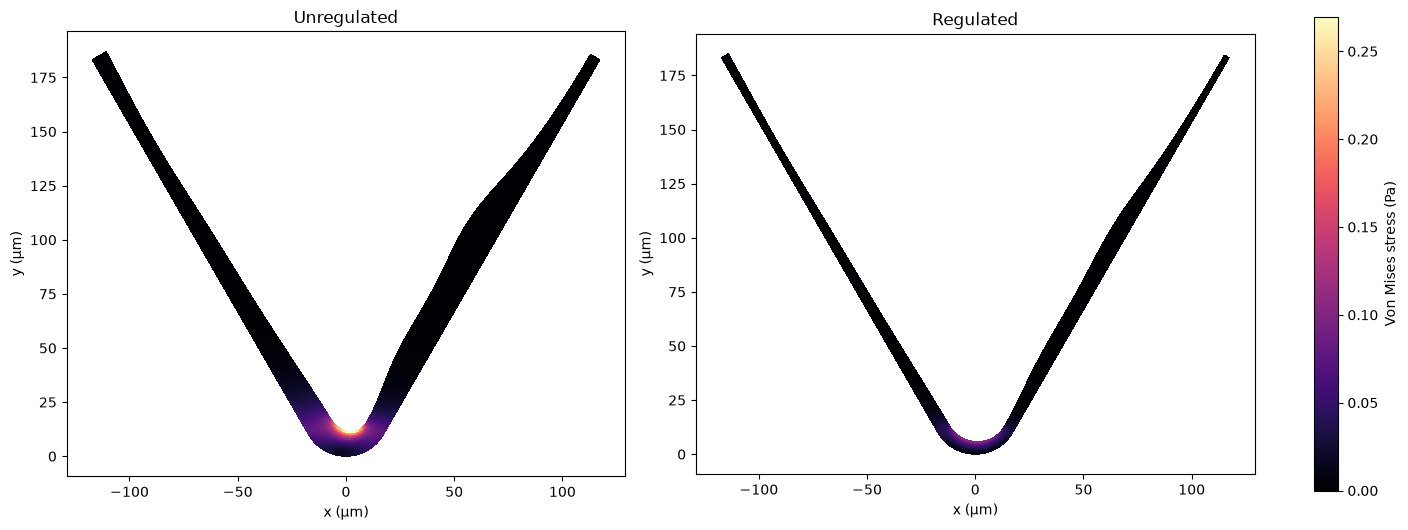

=== Effect of 50% Thickness Reduction ===
Maximum principal strain change: -61.44%
Maximum von Mises stress change:  -60.54%
Mean von Mises stress change:     -55.04%


In [43]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True,
)

# Shared colour scale
vmax = max(
    r["sigma_e"].max()
    for r in paired_bellows_results.values()
)

for ax, (condition, r) in zip(
    axes,
    paired_bellows_results.items(),
):

    points = r["points_um"]

    plot = ax.tripcolor(
        points[:, 0],
        points[:, 1],
        r["triangles"],
        facecolors=r["sigma_e"],
        shading="flat",
        cmap="magma",
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(condition.capitalize())
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    ax.set_aspect("equal")

fig.colorbar(
    plot,
    ax=axes,
    label="Von Mises stress (Pa)",
    shrink=0.8,
)

plt.show()

u = paired_bellows_results["unregulated"]
r = paired_bellows_results["regulated"]

def percentage_change(regulated, unregulated):
    return 100 * (regulated / unregulated - 1)

# Maximum principal strain
strain_change = percentage_change(
    r["max_principal_strain"],
    u["max_principal_strain"],
)

# Maximum von Mises stress
stress_change = percentage_change(
    r["global_peak"],
    u["global_peak"],
)

# Area-weighted mean stress
mean_u = np.average(
    u["sigma_e"],
    weights=u["areas"],
)

mean_r = np.average(
    r["sigma_e"],
    weights=r["areas"],
)

mean_stress_change = percentage_change(mean_r, mean_u)

print("=== Effect of 50% Thickness Reduction ===")

print(f"Maximum principal strain change: {strain_change:+.2f}%")
print(f"Maximum von Mises stress change:  {stress_change:+.2f}%")
print(f"Mean von Mises stress change:     {mean_stress_change:+.2f}%")

## 31. Stochastic Bellows-Deformation Analysis

### Objective

Our first paired simulation demonstrated that hypothetical 50%
biofilm thinning reduced the maximum principal strain and von Mises
equivalent stress under prescribed bellows movement.

However, this result was obtained from a single stochastic morphology.

We therefore repeat the experiment across 20 independent biofilm
thickness profiles.

### Paired geometry

For each random seed, we generate an unregulated biofilm:

$$
h_u(s)=h_0+r(s)
$$

The corresponding regulated biofilm is:

$$
\boxed{
h_r(s)=0.5h_u(s)
}
$$

Both biofilms share the same underlying morphology and are attached
to the same bellows geometry.

### Controlled loading

All simulations use the same prescribed bellows deformation:

$$
\theta_0=60^\circ
\rightarrow
\theta_1=60.5^\circ
$$

Material properties remain unchanged:

$$
E=64\ \mathrm{Pa},\qquad \nu=0.3
$$

### Evaluation

For each paired simulation, we calculate:

1. Maximum principal strain.
2. Maximum von Mises equivalent stress.
3. Area-weighted mean von Mises stress.

We then compare the percentage changes across all 20 pairs.

This analysis investigates the robustness of the predicted geometric
effect under the assumed bellows deformation model.

It does not establish actual biofilm fracture or detachment.

In [44]:
import pandas as pd

N_SAMPLES = 20
ALPHA = 0.5

bellows_ensemble_results = []

for seed in range(N_SAMPLES):

    # Generate stochastic unregulated thickness
    h_u = random_height_profile(
        s_uniform,
        mean_height=10.0,
        roughness=3.0,
        n_features=10,
        min_height=2.0,
        rng=np.random.default_rng(seed),
    )

    # Hypothetical regulation
    h_r = ALPHA * h_u

    for condition, thickness in {
        "unregulated": h_u,
        "regulated": h_r,
    }.items():

        # Construct curved mesh
        points, triangles, boundaries = build_curved_layer_mesh(
            substrate_points=crevice_initial_uniform,
            thickness=thickness,
            ny=15,
            normal_side="left",
        )

        # Solve structural FEM
        result = solve_curved_biofilm(
            points=points,
            triangles=triangles,
            boundaries=boundaries,
            substrate_displacement=bellows_displacement,
            E=64.0,
            nu=0.3,
        )

        # Area-weighted mean stress
        mean_stress = np.average(
            result["sigma_e"],
            weights=result["areas"],
        )

        bellows_ensemble_results.append({
            "seed": seed,
            "condition": condition,
            "mean_thickness": thickness.mean(),
            "max_strain": result["max_principal_strain"],
            "max_stress": result["global_peak"],
            "mean_stress": mean_stress,
        })

    print(f"Completed seed {seed + 1}/{N_SAMPLES}")

bellows_df = pd.DataFrame(bellows_ensemble_results)

print(f"\nCompleted {len(bellows_df)} FEM simulations.")

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.363906e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.908901e-18 (rel: 2.865960e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: updating variables...
sfepy: ...done
sfepy: setting u

In [45]:
comparison = bellows_df.pivot(
    index="seed",
    columns="condition",
    values=["max_strain", "max_stress", "mean_stress"],
)

metrics = ["max_strain", "max_stress", "mean_stress"]

paired_changes = pd.DataFrame(index=comparison.index)

for metric in metrics:

    unregulated = comparison[metric]["unregulated"]
    regulated = comparison[metric]["regulated"]

    paired_changes[metric] = (
        regulated / unregulated - 1
    ) * 100

print("=== Stochastic Bellows-Deformation Results ===")

for metric in metrics:

    changes = paired_changes[metric]

    print(f"\n{metric}")
    print(f"Mean change:   {changes.mean():+.2f}%")
    print(f"Median change: {changes.median():+.2f}%")
    print(f"Minimum:       {changes.min():+.2f}%")
    print(f"Maximum:       {changes.max():+.2f}%")

    print(
        f"Pairs with reduction: "
        f"{(changes < 0).sum()}/{N_SAMPLES}"
    )

=== Stochastic Bellows-Deformation Results ===

max_strain
Mean change:   -60.37%
Median change: -60.84%
Minimum:       -67.33%
Maximum:       -53.38%
Pairs with reduction: 20/20

max_stress
Mean change:   -59.57%
Median change: -60.13%
Minimum:       -65.51%
Maximum:       -53.07%
Pairs with reduction: 20/20

mean_stress
Mean change:   -52.22%
Median change: -53.53%
Minimum:       -57.48%
Maximum:       -42.61%
Pairs with reduction: 20/20


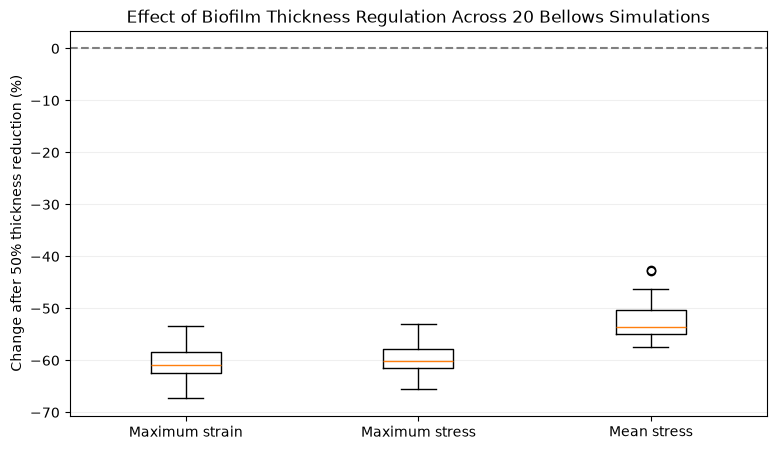

In [46]:
fig, ax = plt.subplots(figsize=(9, 5))

data = [
    paired_changes["max_strain"],
    paired_changes["max_stress"],
    paired_changes["mean_stress"],
]

ax.boxplot(
    data,
    tick_labels=[
        "Maximum strain",
        "Maximum stress",
        "Mean stress",
    ],
)

ax.axhline(
    0,
    color="gray",
    linestyle="--",
)

ax.set_ylabel("Change after 50% thickness reduction (%)")

ax.set_title(
    "Effect of Biofilm Thickness Regulation "
    "Across 20 Bellows Simulations"
)

ax.grid(axis="y", alpha=0.2)

plt.show()

## 32. Mesh Convergence of the Curved Biofilm FEM

### Objective

Our stochastic simulations predict that hypothetical 50% biofilm
thinning reduces maximum and mean equivalent stress under prescribed
bellows deformation.

Before interpreting these results, we must verify that the calculated
mechanical quantities are sufficiently insensitive to mesh resolution.

### Refinement strategy

We refine the mesh in both directions:

- Along the bellows surface.
- Through the biofilm thickness.

The underlying bellows geometry, stochastic thickness profile,
material properties, and prescribed displacement remain unchanged.

We compare:

1. Maximum von Mises stress.
2. Area-weighted mean von Mises stress.
3. Maximum principal strain.
4. Percentage reduction between regulated and unregulated biofilms.

### Relative convergence error

For a quantity $Q$, the relative difference between successive
mesh resolutions is:

$$
\boxed{
\delta_Q=
\frac{|Q_{\mathrm{fine}}-Q_{\mathrm{coarse}}|}
{|Q_{\mathrm{fine}}|}
\times100\%
}
$$

Convergence is supported when the relative differences decrease
and approach an acceptably small value.

Maximum stress may require particular attention because localized
stress concentrations can be mesh-dependent.

In [47]:
mesh_resolutions = [
    (250, 8),
    (500, 15),
    (750, 23),
    (1000, 30),
]

convergence_results = []

# Use the original stochastic profile from our paired experiment
h_reference = h_uniform.copy()

for n_surface, ny_test in mesh_resolutions:

    # Common material-coordinate grid
    s_test = np.linspace(
        s_uniform.min(),
        s_uniform.max(),
        n_surface
    )

    # Interpolate the SAME reference thickness profile
    h_test = np.interp(
        s_test,
        s_uniform,
        h_reference
    )

    # Interpolate the initial substrate geometry
    substrate_test = np.column_stack([
        np.interp(
            s_test,
            s_uniform,
            crevice_initial_uniform[:, 0]
        ),
        np.interp(
            s_test,
            s_uniform,
            crevice_initial_uniform[:, 1]
        ),
    ])

    # Interpolate prescribed bellows displacement
    displacement_test = np.column_stack([
        np.interp(
            s_test,
            s_uniform,
            bellows_displacement[:, 0]
        ),
        np.interp(
            s_test,
            s_uniform,
            bellows_displacement[:, 1]
        ),
    ])

    for condition, thickness in {
        "unregulated": h_test,
        "regulated": 0.5 * h_test,
    }.items():

        points, triangles, boundaries = build_curved_layer_mesh(
            substrate_points=substrate_test,
            thickness=thickness,
            ny=ny_test,
            normal_side="left",
        )

        result = solve_curved_biofilm(
            points=points,
            triangles=triangles,
            boundaries=boundaries,
            substrate_displacement=displacement_test,
            E=64.0,
            nu=0.3,
        )

        convergence_results.append({
            "n_surface": n_surface,
            "ny": ny_test,
            "condition": condition,
            "elements": len(triangles),
            "max_stress": result["global_peak"],
            "mean_stress": np.average(
                result["sigma_e"],
                weights=result["areas"]
            ),
            "max_strain": result["max_principal_strain"],
        })

        print(
            f"N={n_surface:4d}, ny={ny_test:2d} | "
            f"{condition:12s} | "
            f"Max stress={result['global_peak']:.6f} Pa"
        )

convergence_df = pd.DataFrame(convergence_results)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (4000, 4000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.00 s
sfepy: matrix structural nonzeros: 51880 (3.24e-01% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.001960e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.00 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.00 [s]
sfepy: nls: iter: 1, residual: 1.492480e-18 (rel: 1.489560e-15)
sfepy: solved in 1 steps in 0.01 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
N= 250, ny= 8 | unregulated  | Max stress=0.259431 Pa
sfepy: up

In [48]:
metrics = [
    "max_stress",
    "mean_stress",
    "max_strain",
]

for condition in ["unregulated", "regulated"]:

    subset = convergence_df[
        convergence_df["condition"] == condition
    ].sort_values("elements")

    print(f"\n=== {condition.upper()} ===")

    for metric in metrics:

        values = subset[metric].to_numpy()

        changes = (
            np.abs(np.diff(values))
            / np.abs(values[1:])
        ) * 100

        print(f"\n{metric}")

        for i, change in enumerate(changes):
            print(
                f"Mesh {i+1} → {i+2}: "
                f"{change:.4f}%"
            )


=== UNREGULATED ===

max_stress
Mesh 1 → 2: 3.6988%
Mesh 2 → 3: 2.1047%
Mesh 3 → 4: 0.1520%

mean_stress
Mesh 1 → 2: 0.7707%
Mesh 2 → 3: 0.0539%
Mesh 3 → 4: 0.0399%

max_strain
Mesh 1 → 2: 0.6255%
Mesh 2 → 3: 0.8174%
Mesh 3 → 4: 0.5516%

=== REGULATED ===

max_stress
Mesh 1 → 2: 1.1111%
Mesh 2 → 3: 1.1222%
Mesh 3 → 4: 0.1375%

mean_stress
Mesh 1 → 2: 1.8751%
Mesh 2 → 3: 0.1377%
Mesh 3 → 4: 0.0961%

max_strain
Mesh 1 → 2: 0.4531%
Mesh 2 → 3: 0.5819%
Mesh 3 → 4: 0.5190%


In [49]:
comparison = convergence_df.pivot(
    index="elements",
    columns="condition",
    values=["max_stress", "mean_stress", "max_strain"]
)

print("=== Convergence of Regulation Effect ===")

for metric in metrics:

    u = comparison[metric]["unregulated"]
    r = comparison[metric]["regulated"]

    reduction = (1 - r / u) * 100

    print(f"\n{metric}")

    for elements, value in reduction.items():
        print(
            f"{elements:6d} triangles | "
            f"Reduction = {value:.3f}%"
        )

=== Convergence of Regulation Effect ===

max_stress
  3984 triangles | Reduction = 59.484%
 14970 triangles | Reduction = 60.544%
 34454 triangles | Reduction = 60.936%
 59940 triangles | Reduction = 61.049%

mean_stress
  3984 triangles | Reduction = 54.544%
 14970 triangles | Reduction = 55.037%
 34454 triangles | Reduction = 55.074%
 59940 triangles | Reduction = 55.099%

max_strain
  3984 triangles | Reduction = 61.025%
 14970 triangles | Reduction = 61.443%
 34454 triangles | Reduction = 61.535%
 59940 triangles | Reduction = 61.522%


## 33. Sensitivity to Bellows Opening Angle

### Objective

Our previous simulations investigated biofilm deformation under a
prescribed bellows opening-angle change of:

$$
60^\circ\rightarrow60.5^\circ
$$

We now investigate how the calculated mechanical response varies
with the magnitude of bellows deformation.

### Bellows kinematics

The bellows deformation is described by:

$$
\theta_0\rightarrow\theta_0+\Delta\theta
$$

where $\Delta\theta$ represents the change in opening angle.

For each final configuration, we preserve the material length
of the rounded fold by adjusting its radius:

$$
\boxed{
R_1=R_0\frac{\pi-\theta_0}{\pi-\theta_1}
}
$$

The displacement of corresponding material points is:

$$
\boxed{
\mathbf u_b(s)=
\mathbf r(s,\theta_1)-\mathbf r(s,\theta_0)
}
$$

### Mechanical analysis

We apply the resulting displacement to the biofilm–substrate
interface and calculate the internal strain and stress.

Both regulated and unregulated biofilms experience identical
bellows movement.

We investigate whether thickness reduction consistently
decreases mechanical stress across different deformation
magnitudes.

### Limitations

The bellows geometry is an engineering approximation.

The model uses small-strain linear elasticity and does not
account for geometric nonlinearities associated with finite
rotations.

Consequently, large angle changes cannot be interpreted
reliably without further verification or a geometrically
nonlinear formulation.

In [50]:
ANGLE_CHANGES = [0.1, 0.25, 0.5, 1.0]

THETA_INITIAL = 60.0

angle_displacements = {}

for delta_theta in ANGLE_CHANGES:

    theta_final = THETA_INITIAL + delta_theta

    deformation_test = deform_rounded_bellows(
        segment_length=200.0,
        initial_angle_deg=THETA_INITIAL,
        final_angle_deg=theta_final,
        initial_radius=20.0,
    )

    # Resample onto the SAME material-coordinate grid
    p0 = resample_bellows(
        deformation_test["initial_points"],
        deformation_test["s_initial"],
        s_uniform,
    )

    p1 = resample_bellows(
        deformation_test["final_points"],
        deformation_test["s_final"],
        s_uniform,
    )

    # Reflect into the upward-opening crevice
    reflection_level = p0[:, 1].max()

    p0[:, 1] = reflection_level - p0[:, 1]
    p1[:, 1] = reflection_level - p1[:, 1]

    # Common translation
    shift = min(p0[:, 1].min(), p1[:, 1].min())

    p0[:, 1] -= shift
    p1[:, 1] -= shift

    # Verify reference geometry
    assert np.allclose(
        p0,
        crevice_initial_uniform,
        atol=1e-8,
    )

    # Calculate material-point displacement
    displacement = p1 - p0

    angle_displacements[delta_theta] = displacement

    print(
        f"Δθ={delta_theta:.2f}° | "
        f"Maximum substrate displacement="
        f"{np.linalg.norm(displacement, axis=1).max():.6f} μm"
    )

Δθ=0.10° | Maximum substrate displacement=0.156817 μm
Δθ=0.25° | Maximum substrate displacement=0.391893 μm
Δθ=0.50° | Maximum substrate displacement=0.783285 μm
Δθ=1.00° | Maximum substrate displacement=1.564559 μm


In [51]:
NY_ANGLE = 15

angle_results = []

for delta_theta, displacement in angle_displacements.items():

    for condition, thickness in {
        "unregulated": h_uniform,
        "regulated": 0.5 * h_uniform,
    }.items():

        points, triangles, boundaries = build_curved_layer_mesh(
            substrate_points=crevice_initial_uniform,
            thickness=thickness,
            ny=NY_ANGLE,
            normal_side="left",
        )

        result = solve_curved_biofilm(
            points=points,
            triangles=triangles,
            boundaries=boundaries,
            substrate_displacement=displacement,
            E=64.0,
            nu=0.3,
        )

        mean_stress = np.average(
            result["sigma_e"],
            weights=result["areas"],
        )

        angle_results.append({
            "delta_theta": delta_theta,
            "condition": condition,
            "max_stress": result["global_peak"],
            "mean_stress": mean_stress,
            "max_strain": result["max_principal_strain"],
        })

angle_df = pd.DataFrame(angle_results)

print(angle_df)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 2.667538e-04 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 6.925198e-19 (rel: 2.596101e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: updating variables...
sfepy: ...done
sfepy: setting u

In [52]:
comparison = angle_df.pivot(
    index="delta_theta",
    columns="condition",
    values=["max_stress", "mean_stress", "max_strain"],
)

print("=== Bellows Angle Sensitivity ===")

for metric in ["max_stress", "mean_stress", "max_strain"]:

    u = comparison[metric]["unregulated"]
    r = comparison[metric]["regulated"]

    reduction = (1 - r / u) * 100

    print(f"\n{metric}")

    for angle, value in reduction.items():
        print(
            f"Δθ={angle:.2f}° | "
            f"Reduction={value:.3f}%"
        )

=== Bellows Angle Sensitivity ===

max_stress
Δθ=0.10° | Reduction=60.539%
Δθ=0.25° | Reduction=60.541%
Δθ=0.50° | Reduction=60.544%
Δθ=1.00° | Reduction=60.550%

mean_stress
Δθ=0.10° | Reduction=57.079%
Δθ=0.25° | Reduction=56.309%
Δθ=0.50° | Reduction=55.037%
Δθ=1.00° | Reduction=52.568%

max_strain
Δθ=0.10° | Reduction=61.435%
Δθ=0.25° | Reduction=61.438%
Δθ=0.50° | Reduction=61.443%
Δθ=1.00° | Reduction=61.453%


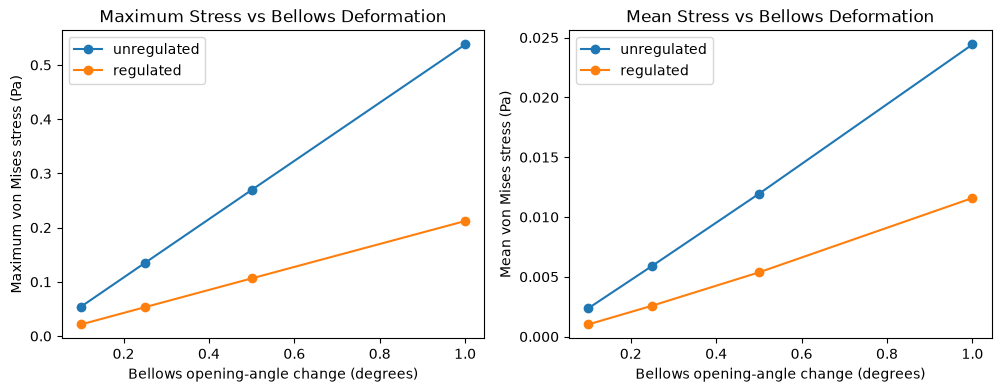

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for condition in ["unregulated", "regulated"]:

    subset = angle_df[
        angle_df["condition"] == condition
    ].sort_values("delta_theta")

    axes[0].plot(
        subset["delta_theta"],
        subset["max_stress"],
        "o-",
        label=condition,
    )

    axes[1].plot(
        subset["delta_theta"],
        subset["mean_stress"],
        "o-",
        label=condition,
    )

axes[0].set_xlabel("Bellows opening-angle change (degrees)")
axes[0].set_ylabel("Maximum von Mises stress (Pa)")
axes[0].set_title("Maximum Stress vs Bellows Deformation")
axes[0].legend()

axes[1].set_xlabel("Bellows opening-angle change (degrees)")
axes[1].set_ylabel("Mean von Mises stress (Pa)")
axes[1].set_title("Mean Stress vs Bellows Deformation")
axes[1].legend()

plt.show()

## 34. Sensitivity to Bellows Fold Radius

### Objective

Our previous simulations demonstrated that hypothetical 50%
biofilm thinning consistently reduced mechanical stress under
small prescribed bellows opening-angle changes.

We now investigate how the initial radius of the rounded bellows
fold influences the mechanical response.

### Fold curvature

The curvature of a circular fold is:

$$
\boxed{
\kappa=\frac{1}{R}
}
$$

where $R$ is the radius of curvature.

Smaller radii correspond to sharper folds.

### Length-preserving deformation

We prescribe:

$$
\theta_0=60^\circ,\qquad
\theta_1=60.5^\circ
$$

The final radius is determined by preserving the material length
of the curved fold:

$$
\boxed{
R_1=R_0\frac{\pi-\theta_0}{\pi-\theta_1}
}
$$

The resulting curvature change is:

$$
\Delta\kappa=\frac{1}{R_1}-\frac{1}{R_0}
$$

### Mechanical comparison

For each initial radius, we generate paired regulated and
unregulated biofilms and apply the corresponding prescribed
bellows displacement.

We compare maximum principal strain, maximum von Mises stress,
and area-weighted mean equivalent stress.

The analysis investigates sensitivity to assumed fold geometry,
not experimentally validated bellows behaviour.

In [54]:
RADII = [15.0, 20.0, 25.0, 30.0, 40.0]

THETA_0 = 60.0
THETA_1 = 60.5

N_SURFACE = 500
NY_RADIUS = 15

radius_results = []

for R0 in RADII:

    # --------------------------------------------------
    # 1. Generate length-preserving bellows deformation
    # --------------------------------------------------

    deformation_R = deform_rounded_bellows(
        segment_length=200.0,
        initial_angle_deg=THETA_0,
        final_angle_deg=THETA_1,
        initial_radius=R0,
    )

    # Material-coordinate grid
    s_R = np.linspace(
        0,
        deformation_R["s_initial"][-1],
        N_SURFACE,
    )

    # Initial and final bellows configurations
    p0_R = resample_bellows(
        deformation_R["initial_points"],
        deformation_R["s_initial"],
        s_R,
    )

    p1_R = resample_bellows(
        deformation_R["final_points"],
        deformation_R["s_final"],
        s_R,
    )

    # --------------------------------------------------
    # 2. Reflect into upward-opening V
    # --------------------------------------------------

    reflection_level = p0_R[:, 1].max()

    p0_R[:, 1] = reflection_level - p0_R[:, 1]
    p1_R[:, 1] = reflection_level - p1_R[:, 1]

    # Common translation
    shift = min(p0_R[:, 1].min(), p1_R[:, 1].min())

    p0_R[:, 1] -= shift
    p1_R[:, 1] -= shift

    # Bellows displacement
    displacement_R = p1_R - p0_R

    # --------------------------------------------------
    # 3. Generate stochastic biofilm thickness
    # --------------------------------------------------

    # Normalized material coordinate
    s_normalized = s_R / s_R[-1]

    h_u = random_height_profile(
        s_normalized,
        mean_height=10.0,
        roughness=3.0,
        n_features=10,
        min_height=2.0,
        rng=np.random.default_rng(42),
    )

    h_r = 0.5 * h_u

    # --------------------------------------------------
    # 4. Solve paired FEM simulations
    # --------------------------------------------------

    for condition, thickness in {
        "unregulated": h_u,
        "regulated": h_r,
    }.items():

        points, triangles, boundaries = build_curved_layer_mesh(
            substrate_points=p0_R,
            thickness=thickness,
            ny=NY_RADIUS,
            normal_side="left",
        )

        # Preliminary geometric checks
        P = points[triangles]

        AB = P[:, 1] - P[:, 0]
        AC = P[:, 2] - P[:, 0]

        signed_areas = 0.5 * (
            AB[:, 0] * AC[:, 1]
            - AB[:, 1] * AC[:, 0]
        )

        base_curve = points[boundaries["substrate"]]
        top_curve = points[boundaries["top"]]

        polygon = Polygon(
            np.vstack([base_curve, top_curve[::-1]])
        )

        if (
            np.any(signed_areas <= 0)
            or not polygon.is_valid
            or not LineString(top_curve).is_simple
        ):
            raise ValueError(
                f"Invalid geometry at R={R0}, "
                f"condition={condition}"
            )

        # Solve FEM
        result = solve_curved_biofilm(
            points=points,
            triangles=triangles,
            boundaries=boundaries,
            substrate_displacement=displacement_R,
            E=64.0,
            nu=0.3,
        )

        mean_stress = np.average(
            result["sigma_e"],
            weights=result["areas"],
        )

        radius_results.append({
            "radius": R0,
            "condition": condition,
            "max_stress": result["global_peak"],
            "mean_stress": mean_stress,
            "max_strain": result["max_principal_strain"],
            "max_displacement": result["max_displacement_um"],
        })

        print(
            f"R={R0:5.1f} μm | "
            f"{condition:12s} | "
            f"Max stress={result['global_peak']:.6f} Pa | "
            f"Mean stress={mean_stress:.6f} Pa"
        )

radius_df = pd.DataFrame(radius_results)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.247274e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.161813e-18 (rel: 2.534979e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
R= 15.0 μm | unregulated  | Max stress=0.376198 Pa | Mean st

In [55]:
radius_comparison = radius_df.pivot(
    index="radius",
    columns="condition",
    values=["max_stress", "mean_stress", "max_strain"],
)

print("=== Fold-Radius Sensitivity ===")

for metric in ["max_stress", "mean_stress", "max_strain"]:

    u = radius_comparison[metric]["unregulated"]
    r = radius_comparison[metric]["regulated"]

    reduction = (1 - r / u) * 100

    print(f"\n{metric}")

    for radius, value in reduction.items():
        print(
            f"R={radius:5.1f} μm | "
            f"Reduction={value:.3f}%"
        )

=== Fold-Radius Sensitivity ===

max_stress
R= 15.0 μm | Reduction=65.219%
R= 20.0 μm | Reduction=61.129%
R= 25.0 μm | Reduction=58.951%
R= 30.0 μm | Reduction=57.637%
R= 40.0 μm | Reduction=55.872%

mean_stress
R= 15.0 μm | Reduction=56.053%
R= 20.0 μm | Reduction=54.471%
R= 25.0 μm | Reduction=53.107%
R= 30.0 μm | Reduction=52.004%
R= 40.0 μm | Reduction=50.468%

max_strain
R= 15.0 μm | Reduction=66.757%
R= 20.0 μm | Reduction=61.942%
R= 25.0 μm | Reduction=59.470%
R= 30.0 μm | Reduction=58.016%
R= 40.0 μm | Reduction=56.125%


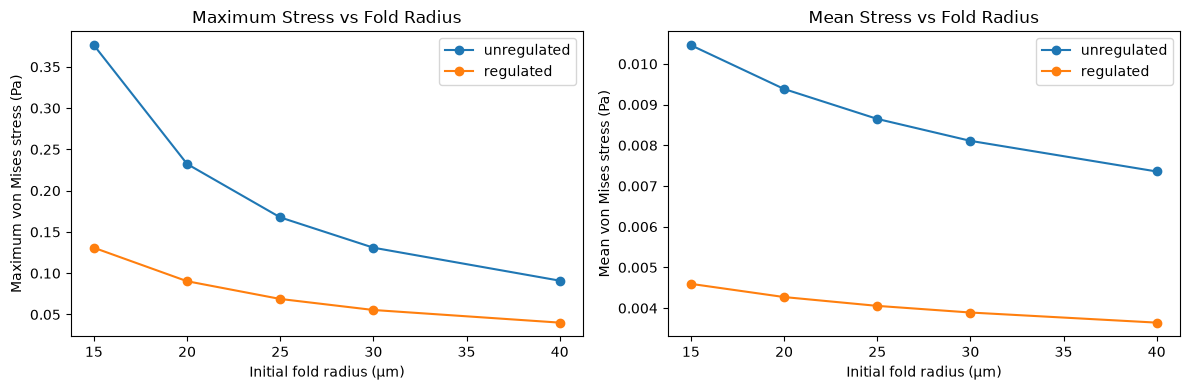

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for condition in ["unregulated", "regulated"]:

    subset = radius_df[
        radius_df["condition"] == condition
    ].sort_values("radius")

    axes[0].plot(
        subset["radius"],
        subset["max_stress"],
        "o-",
        label=condition,
    )

    axes[1].plot(
        subset["radius"],
        subset["mean_stress"],
        "o-",
        label=condition,
    )

axes[0].set_xlabel("Initial fold radius (μm)")
axes[0].set_ylabel("Maximum von Mises stress (Pa)")
axes[0].set_title("Maximum Stress vs Fold Radius")
axes[0].legend()

axes[1].set_xlabel("Initial fold radius (μm)")
axes[1].set_ylabel("Mean von Mises stress (Pa)")
axes[1].set_title("Mean Stress vs Fold Radius")
axes[1].legend()

plt.tight_layout()
plt.show()

## 35. Dimensionless Thickness-to-Radius Analysis

### Objective

Our fold-radius sensitivity study demonstrated that sharper folds
produce greater mechanical stresses under the prescribed bellows
deformation.

We now investigate whether the mechanical response can be
characterized using the dimensionless thickness-to-radius ratio:

$$
\boxed{
\chi=\frac{\overline h}{R_0}
}
$$

where $\overline h$ is the mean biofilm thickness and $R_0$
is the initial bellows fold radius.

### Physical motivation

For a thin layer undergoing bending, strain depends on the
distance from the reference surface and the change in curvature:

$$
\varepsilon_{\mathrm{bend}}\approx z\Delta\kappa
$$

For our idealized length-preserving bellows:

$$
\Delta\kappa
=
-\frac{\Delta\theta}{R_0(\pi-\theta_0)}
$$

Consequently, a characteristic bending strain scales approximately as:

$$
\boxed{
|\varepsilon_{\mathrm{bend}}|
\sim
\frac{h}{R_0}
\frac{|\Delta\theta|}{\pi-\theta_0}
}
$$

This suggests that the ratio $h/R_0$ may help characterize
the mechanical response of biofilm attached to the rounded fold.

However, this scaling is an approximation and does not account
for the full two-dimensional stress distribution.

We investigate whether the FEM results are consistent with
this proposed relationship.

In [57]:
# Nominal mean thicknesses used in the radius experiment
H_UNREGULATED = 10.0
H_REGULATED = 5.0

radius_df["h_over_R"] = np.where(
    radius_df["condition"] == "unregulated",
    H_UNREGULATED / radius_df["radius"],
    H_REGULATED / radius_df["radius"]
)

print(
    radius_df[
        ["radius", "condition", "h_over_R", "max_stress"]
    ]
)

   radius    condition  h_over_R  max_stress
0    15.0  unregulated  0.666667    0.376198
1    15.0    regulated  0.333333    0.130846
2    20.0  unregulated  0.500000    0.232342
3    20.0    regulated  0.250000    0.090313
4    25.0  unregulated  0.400000    0.167634
5    25.0    regulated  0.200000    0.068813
6    30.0  unregulated  0.333333    0.130917
7    30.0    regulated  0.166667    0.055460
8    40.0  unregulated  0.250000    0.090988
9    40.0    regulated  0.125000    0.040151


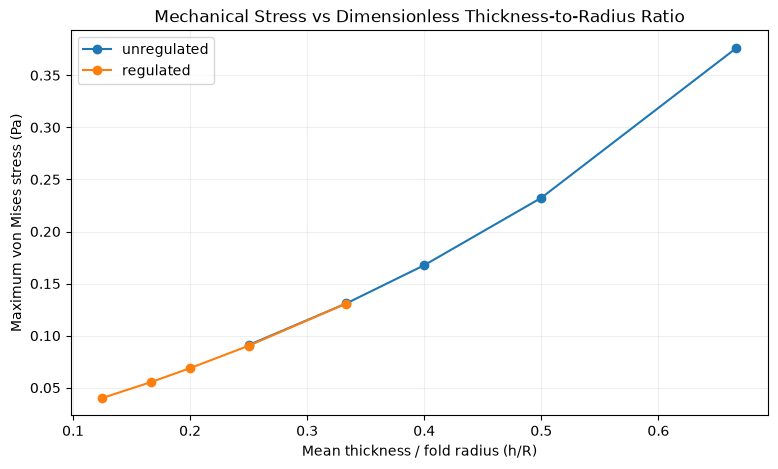

In [58]:
fig, ax = plt.subplots(figsize=(9, 5))

for condition in ["unregulated", "regulated"]:

    subset = radius_df[
        radius_df["condition"] == condition
    ].sort_values("h_over_R")

    ax.plot(
        subset["h_over_R"],
        subset["max_stress"],
        "o-",
        label=condition
    )

ax.set_xlabel("Mean thickness / fold radius (h/R)")
ax.set_ylabel("Maximum von Mises stress (Pa)")
ax.set_title("Mechanical Stress vs Dimensionless Thickness-to-Radius Ratio")

ax.legend()
ax.grid(alpha=0.2)

plt.show()

## 36. Verifying Principal Tensile Stress and Strain

We extend the structural FEM postprocessing to calculate
mechanical indicators associated with tensile loading.

### Principal tensile stress

The maximum principal tensile stress is:

$$
\boxed{
\sigma_t=\max(0,\sigma_1,\sigma_2,\sigma_{zz})
}
$$

where the in-plane principal stresses are:

$$
\sigma_{1,2}
=
\frac{\sigma_{xx}+\sigma_{yy}}{2}
\pm
\sqrt{
\left(\frac{\sigma_{xx}-\sigma_{yy}}{2}\right)^2
+\tau_{xy}^2
}
$$

### Principal tensile strain

The maximum principal tensile strain is:

$$
\boxed{
\varepsilon_t=\max(0,\varepsilon_1,\varepsilon_2)
}
$$

These indicators distinguish tensile deformation from
compressive deformation.

They are not calibrated fracture criteria.

We verify the calculations using analytical stress states
before applying them to bellows-induced deformation.

In [59]:
import numpy as np

def calculate_principal_tensile_stress(
    sxx, syy, txy, szz
):
    mean = (sxx + syy) / 2

    radius = np.sqrt(
        ((sxx - syy) / 2)**2
        + txy**2
    )

    sigma1 = mean + radius
    sigma2 = mean - radius

    return max(0.0, sigma1, sigma2, szz)


# Test 1: Uniaxial tension
result_1 = calculate_principal_tensile_stress(
    sxx=10.0,
    syy=0.0,
    txy=0.0,
    szz=0.0,
)

assert np.isclose(result_1, 10.0)


# Test 2: Hydrostatic compression
result_2 = calculate_principal_tensile_stress(
    sxx=-10.0,
    syy=-10.0,
    txy=0.0,
    szz=-10.0,
)

assert np.isclose(result_2, 0.0)


# Test 3: Pure shear
result_3 = calculate_principal_tensile_stress(
    sxx=0.0,
    syy=0.0,
    txy=5.0,
    szz=0.0,
)

assert np.isclose(result_3, 5.0)

print("All analytical principal-stress tests passed.")

All analytical principal-stress tests passed.


## 37. Tensile Vulnerability Under Bellows Deformation

We compare the principal tensile stress and strain of
regulated and unregulated biofilms under identical
bellows-induced deformation.

The prescribed opening-angle change is:

$$
60^\circ\rightarrow60.5^\circ
$$

The regulated biofilm is assumed to retain 50% of
the unregulated biofilm thickness:

$$
h_r(s)=0.5h_u(s)
$$

Material properties remain unchanged.

We calculate:

1. Maximum principal tensile stress.
2. Maximum principal tensile strain.
3. Area-weighted mean principal tensile stress.
4. Area-weighted mean principal tensile strain.

These metrics quantify tensile loading within the
biofilm but do not predict fracture or detachment.

In [60]:
tensile_results = {}

for condition, mesh_data in paired_meshes.items():

    result = solve_curved_biofilm(
        points=mesh_data["points"],
        triangles=mesh_data["triangles"],
        boundaries=mesh_data["boundaries"],
        substrate_displacement=bellows_displacement,
        E=64.0,
        nu=0.3,
    )

    tensile_results[condition] = result

    mean_tensile_stress = np.average(
        result["principal_tensile_stress"],
        weights=result["areas"],
    )

    mean_tensile_strain = np.average(
        result["principal_tensile_strain"],
        weights=result["areas"],
    )

    print(f"\n=== {condition.upper()} ===")

    print(
        f"Maximum tensile stress: "
        f"{result['max_tensile_stress']:.6f} Pa"
    )

    print(
        f"Maximum tensile strain: "
        f"{result['max_tensile_strain'] * 100:.4f}%"
    )

    print(
        f"Mean tensile stress: "
        f"{mean_tensile_stress:.6f} Pa"
    )

    print(
        f"Mean tensile strain: "
        f"{mean_tensile_strain * 100:.4f}%"
    )

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.332371e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.400313e-18 (rel: 2.552075e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s

=== UNREGULATED ===
Maximum tensile stress: 0.327963 Pa
Max

In [61]:
u = tensile_results["unregulated"]
r = tensile_results["regulated"]

def reduction_percentage(unregulated, regulated):
    return 100 * (1 - regulated / unregulated)


metrics = [
    ("Maximum tensile stress", "max_tensile_stress"),
    ("Maximum tensile strain", "max_tensile_strain"),
]

print("=== Effect of 50% Thickness Reduction ===")

for label, key in metrics:

    reduction = reduction_percentage(
        u[key],
        r[key],
    )

    print(f"{label}: {reduction:.2f}% reduction")


# Area-weighted mean tensile stress
mean_u = np.average(
    u["principal_tensile_stress"],
    weights=u["areas"],
)

mean_r = np.average(
    r["principal_tensile_stress"],
    weights=r["areas"],
)

print(
    f"Mean tensile stress: "
    f"{reduction_percentage(mean_u, mean_r):.2f}% reduction"
)

=== Effect of 50% Thickness Reduction ===
Maximum tensile stress: 62.22% reduction
Maximum tensile strain: 61.44% reduction
Mean tensile stress: 58.08% reduction


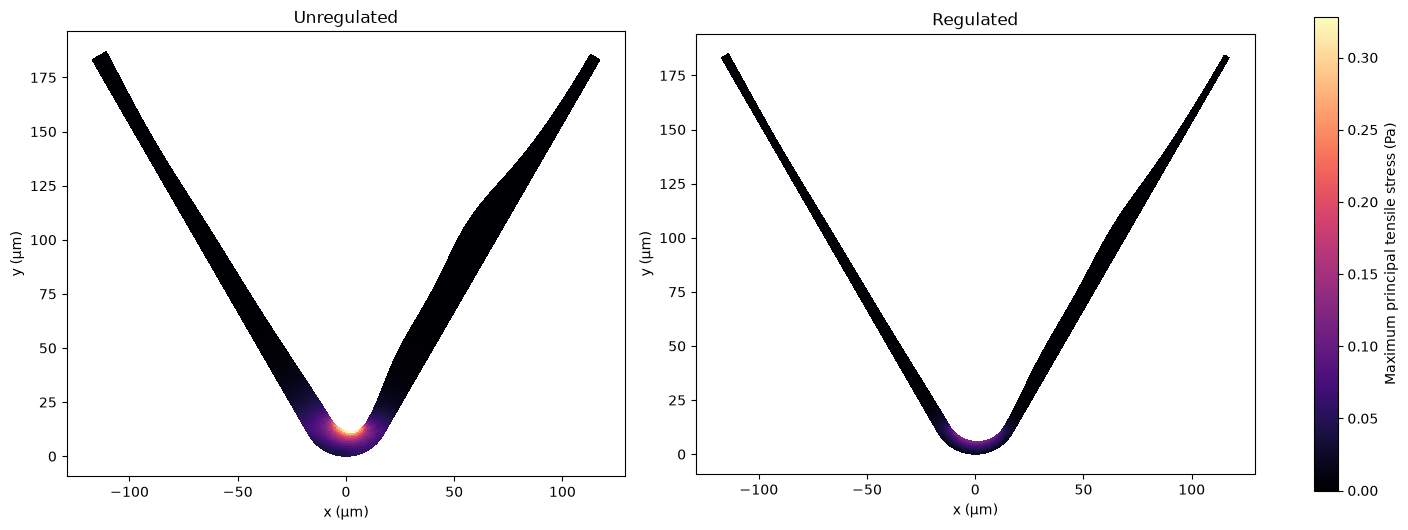

In [62]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True,
)

vmax = max(
    result["principal_tensile_stress"].max()
    for result in tensile_results.values()
)

for ax, (condition, result) in zip(
    axes,
    tensile_results.items(),
):

    points = result["points_um"]

    plot = ax.tripcolor(
        points[:, 0],
        points[:, 1],
        result["triangles"],
        facecolors=result["principal_tensile_stress"],
        shading="flat",
        cmap="magma",
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(condition.capitalize())
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    ax.set_aspect("equal")

fig.colorbar(
    plot,
    ax=axes,
    label="Maximum principal tensile stress (Pa)",
    shrink=0.8,
)

plt.show()

## 38. Sensitivity to Biofilm Material Properties

### Objective

Our structural FEM assumes homogeneous, isotropic linear elasticity.

However, the mechanical properties of bacterial biofilms vary
substantially with species, extracellular matrix composition,
hydration, and measurement conditions.

We therefore investigate how uncertainty in Young's modulus
and Poisson's ratio affects our predicted mechanical response.

### Constitutive relationship

Under plane strain:

$$
\boldsymbol{\sigma}=\mathbf D\boldsymbol{\varepsilon}
$$

where:

$$
\mathbf D=
\frac{E}{(1+\nu)(1-2\nu)}
\begin{bmatrix}
1-\nu & \nu & 0\\
\nu & 1-\nu & 0\\
0 & 0 & \frac{1-2\nu}{2}
\end{bmatrix}
$$

### Young's modulus

For prescribed substrate displacement, changing a spatially
uniform Young's modulus while keeping Poisson's ratio fixed
does not change the displacement or strain fields.

Instead, stress scales proportionally with Young's modulus:

$$
\boldsymbol{\sigma}\propto E
$$

Consequently, if regulated and unregulated biofilms have
identical material properties, their percentage stress
reduction should be independent of the common value of $E$.

### Poisson's ratio

Changing Poisson's ratio modifies the constitutive coupling
between deformation components.

This may change both the spatial stress distribution and
the relative benefit of thickness regulation.

### Limitations

The tested material parameters are illustrative and do not
represent experimentally calibrated properties of our
engineered bacterial strain.

This analysis tests parameter sensitivity within linear
elasticity. It does not account for viscoelasticity,
heterogeneity, or changes in material properties caused
by gamma-PGA regulation.

In [63]:
import pandas as pd
import numpy as np

E_VALUES = [32.0, 64.0, 128.0, 640.0, 6400.0]

E_results = []

for E_test in E_VALUES:

    for condition, mesh_data in paired_meshes.items():

        result = solve_curved_biofilm(
            points=mesh_data["points"],
            triangles=mesh_data["triangles"],
            boundaries=mesh_data["boundaries"],
            substrate_displacement=bellows_displacement,
            E=E_test,
            nu=0.3,
        )

        E_results.append({
            "E": E_test,
            "condition": condition,
            "max_tensile_stress": result["max_tensile_stress"],
            "max_tensile_strain": result["max_tensile_strain"],
            "mean_tensile_stress": np.average(
                result["principal_tensile_stress"],
                weights=result["areas"],
            ),
            "max_displacement": result["max_displacement_um"],
        })

        print(
            f"E={E_test:7.1f} Pa | "
            f"{condition:12s} | "
            f"Max tensile stress="
            f"{result['max_tensile_stress']:.6f} Pa"
        )

E_df = pd.DataFrame(E_results)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 6.661857e-04 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 1.700156e-18 (rel: 2.552075e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
E=   32.0 Pa | unregulated  | Max tensile stress=0.163982 Pa

In [64]:
E_comparison = E_df.pivot(
    index="E",
    columns="condition",
    values=[
        "max_tensile_stress",
        "max_tensile_strain",
        "mean_tensile_stress",
    ],
)

print("=== Young's Modulus Sensitivity ===")

for metric in [
    "max_tensile_stress",
    "max_tensile_strain",
    "mean_tensile_stress",
]:

    u = E_comparison[metric]["unregulated"]
    r = E_comparison[metric]["regulated"]

    reduction = 100 * (1 - r / u)

    print(f"\n{metric}")

    for E_test, value in reduction.items():
        print(
            f"E={E_test:7.1f} Pa | "
            f"Reduction={value:.4f}%"
        )

=== Young's Modulus Sensitivity ===

max_tensile_stress
E=   32.0 Pa | Reduction=62.2169%
E=   64.0 Pa | Reduction=62.2169%
E=  128.0 Pa | Reduction=62.2169%
E=  640.0 Pa | Reduction=62.2169%
E= 6400.0 Pa | Reduction=62.2169%

max_tensile_strain
E=   32.0 Pa | Reduction=61.4433%
E=   64.0 Pa | Reduction=61.4433%
E=  128.0 Pa | Reduction=61.4433%
E=  640.0 Pa | Reduction=61.4433%
E= 6400.0 Pa | Reduction=61.4433%

mean_tensile_stress
E=   32.0 Pa | Reduction=58.0790%
E=   64.0 Pa | Reduction=58.0790%
E=  128.0 Pa | Reduction=58.0790%
E=  640.0 Pa | Reduction=58.0790%
E= 6400.0 Pa | Reduction=58.0790%


In [65]:
for condition in ["unregulated", "regulated"]:

    subset = E_df[
        E_df["condition"] == condition
    ].sort_values("E")

    normalized_stress = (
        subset["max_tensile_stress"].to_numpy()
        / subset["E"].to_numpy()
    )

    assert np.allclose(
        normalized_stress,
        normalized_stress[0],
        rtol=1e-5,
    )

print("Young's modulus scaling verification passed.")

Young's modulus scaling verification passed.


## 39. Sensitivity to Poisson's Ratio

Poisson's ratio controls the coupling between longitudinal
and transverse deformation.

For isotropic linear elasticity:

$$
\nu=-\frac{\varepsilon_{\mathrm{transverse}}}
{\varepsilon_{\mathrm{longitudinal}}}
$$

under uniaxial stress in the linear-elastic regime.

Our baseline model assumes:

$$
\nu=0.3
$$

However, this value has not been experimentally calibrated
for our biofilm.

We therefore investigate:

$$
\nu\in\{0.2,0.3,0.4,0.45\}
$$

while keeping Young's modulus constant.

### Numerical limitation

As $\nu\rightarrow0.5$, an isotropic elastic material
approaches incompressibility.

Standard low-order displacement-based finite elements may
exhibit volumetric locking.

Consequently, the results at larger Poisson's ratios
require particular caution and potentially additional
mesh-convergence verification.

In [66]:
NU_VALUES = [0.2, 0.3, 0.4, 0.45]

nu_results = []

for nu_test in NU_VALUES:

    for condition, mesh_data in paired_meshes.items():

        result = solve_curved_biofilm(
            points=mesh_data["points"],
            triangles=mesh_data["triangles"],
            boundaries=mesh_data["boundaries"],
            substrate_displacement=bellows_displacement,
            E=64.0,
            nu=nu_test,
        )

        nu_results.append({
            "nu": nu_test,
            "condition": condition,
            "max_tensile_stress": result["max_tensile_stress"],
            "max_tensile_strain": result["max_tensile_strain"],
            "mean_tensile_stress": np.average(
                result["principal_tensile_stress"],
                weights=result["areas"],
            ),
        })

        print(
            f"nu={nu_test:.2f} | "
            f"{condition:12s} | "
            f"Max tensile stress="
            f"{result['max_tensile_stress']:.6f} Pa"
        )

nu_df = pd.DataFrame(nu_results)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.123417e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 2.969330e-18 (rel: 2.643124e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
nu=0.20 | unregulated  | Max tensile stress=0.299228 Pa
sfep

In [67]:
nu_comparison = nu_df.pivot(
    index="nu",
    columns="condition",
    values=[
        "max_tensile_stress",
        "max_tensile_strain",
        "mean_tensile_stress",
    ],
)

print("=== Poisson's Ratio Sensitivity ===")

for metric in [
    "max_tensile_stress",
    "max_tensile_strain",
    "mean_tensile_stress",
]:

    u = nu_comparison[metric]["unregulated"]
    r = nu_comparison[metric]["regulated"]

    reduction = 100 * (1 - r / u)

    print(f"\n{metric}")

    for nu_test, value in reduction.items():
        print(
            f"nu={nu_test:.2f} | "
            f"Reduction={value:.3f}%"
        )

=== Poisson's Ratio Sensitivity ===

max_tensile_stress
nu=0.20 | Reduction=61.634%
nu=0.30 | Reduction=62.217%
nu=0.40 | Reduction=63.751%
nu=0.45 | Reduction=66.002%

max_tensile_strain
nu=0.20 | Reduction=61.301%
nu=0.30 | Reduction=61.443%
nu=0.40 | Reduction=61.740%
nu=0.45 | Reduction=61.944%

mean_tensile_stress
nu=0.20 | Reduction=56.695%
nu=0.30 | Reduction=58.079%
nu=0.40 | Reduction=60.179%
nu=0.45 | Reduction=61.731%


## 40. Mapping FEM Results to a Cartesian Grid

### Objective

Our structural FEM uses an unstructured triangular mesh,
whereas the biofilm dispersion model uses a Cartesian grid.

We construct a mapping between these spatial representations
without changing either model's governing equations.

### Area-weighted projection

For each Cartesian cell $G_{ij}$, the mapped stress is:

$$
\boxed{
\overline{\sigma}_{ij}
=
\frac{
\sum_k |G_{ij}\cap T_k|\sigma_k
}{
\sum_k |G_{ij}\cap T_k|
}
}
$$

where $T_k$ represents a triangular FEM element.

### Occupancy fraction

We also calculate the fraction of each Cartesian cell
occupied by biofilm:

$$
\boxed{
\phi_{ij}
=
\frac{
\sum_k |G_{ij}\cap T_k|
}{
|G_{ij}|
}
}
$$

The resulting arrays have shape:

$$
(n_y,n_x)
$$

This representation allows the structural FEM outputs
to be integrated with a grid-based biofilm dispersion model.

The mapping preserves area-weighted quantities but
does not introduce additional mechanical coupling.

In [68]:
from src.grid_mapping import fem_to_grid

# Use the unregulated tensile-stress simulation
result = tensile_results["unregulated"]

points = result["points_um"]

# Grid resolution
NX = 100
NY = 100

# Small padding around biofilm
padding = 5.0

x_edges = np.linspace(
    points[:, 0].min() - padding,
    points[:, 0].max() + padding,
    NX + 1,
)

y_edges = np.linspace(
    points[:, 1].min() - padding,
    points[:, 1].max() + padding,
    NY + 1,
)

grid_result = fem_to_grid(
    points=points,
    triangles=result["triangles"],
    fields={
        "von_mises": result["sigma_e"],
        "tensile_stress": result["principal_tensile_stress"],
        "tensile_strain": result["principal_tensile_strain"],
    },
    x_edges=x_edges,
    y_edges=y_edges,
)

print("Occupancy shape:",
      grid_result["occupancy_fraction"].shape)

print("Tensile stress shape:",
      grid_result["fields"]["tensile_stress"].shape)

Occupancy shape: (100, 100)
Tensile stress shape: (100, 100)


## 41. FEM-to-Grid Conservation Verification

### Objective

We verify that converting our triangular FEM mesh into a Cartesian grid preserves the total biofilm area and the spatial integrals of element-averaged mechanical quantities.

Because the mapping uses exact polygon intersection areas, it should preserve these quantities up to numerical precision, provided the Cartesian grid covers the entire FEM domain.

### 1. Conservation of biofilm area

The total area of the biofilm in the FEM representation is:

$$
A_{\mathrm{FEM}}=\sum_k A_k
$$

where $A_k$ is the area of triangular element $k$.

In the Cartesian representation, each grid cell has an occupancy fraction:

$$
\phi_{ij}=
\frac{\sum_k |T_k\cap G_{ij}|}{|G_{ij}|}
$$

The total biofilm area represented by the grid is therefore:

$$
A_{\mathrm{grid}}=
\sum_{ij}\phi_{ij}|G_{ij}|
$$

For a conservative mapping:

$$
\boxed{
A_{\mathrm{FEM}}=A_{\mathrm{grid}}
}
$$

We quantify the relative area conservation error as:

$$
\boxed{
\delta_A=
\frac{|A_{\mathrm{grid}}-A_{\mathrm{FEM}}|}
{A_{\mathrm{FEM}}}
}
$$

### 2. Conservation of area-integrated mechanical quantities

Our FEM calculates element-averaged mechanical quantities, such as principal tensile stress $\sigma_k$.

The corresponding area integral is:

$$
I_{\mathrm{FEM}}=\sum_k A_k\sigma_k
$$

For each Cartesian cell, the mapped stress is calculated using intersection-area weighting:

$$
\overline{\sigma}_{ij}
=
\frac{
\sum_k |T_k\cap G_{ij}|\sigma_k
}{
\sum_k |T_k\cap G_{ij}|
}
$$

The corresponding area integral in the Cartesian representation is:

$$
I_{\mathrm{grid}}=
\sum_{ij}
\phi_{ij}|G_{ij}|\overline{\sigma}_{ij}
$$

Therefore, conservative mapping requires:

$$
\boxed{
\sum_k A_k\sigma_k
=
\sum_{ij}
\phi_{ij}|G_{ij}|\overline{\sigma}_{ij}
}
$$

The relative conservation error is:

$$
\boxed{
\delta_I=
\frac{|I_{\mathrm{grid}}-I_{\mathrm{FEM}}|}
{|I_{\mathrm{FEM}}|}
}
$$

This verification applies to any element-averaged scalar field mapped using the same area-weighted procedure, provided the grid covers the entire FEM domain.

### 3. Numerical verification

We compare the total biofilm area and the area-integrated principal tensile stress before and after mapping.

The following acceptance criteria are imposed:

$$
\delta_A<10^{-6}
$$

$$
\delta_I<10^{-6}
$$

Both verification tests passed.

### 4. Interpretation

The results demonstrate that our FEM-to-grid mapping conserves:

1. Total biofilm area.
2. Area-integrated principal tensile stress.

This confirms that the conversion from an unstructured triangular mesh to a structured Cartesian grid does not introduce significant errors in these integrated quantities.

However, conservation of area-integrated stress is **not equivalent to conservation of mechanical force or momentum**.

Furthermore, cell averaging may smooth localized stress concentrations, so maximum stress values in the Cartesian representation may differ from those calculated directly using FEM.

The mapping provides a numerically verified interface for transferring spatial mechanical information to the grid-based biofilm dispersion model.

In [69]:
# FEM total area
fem_area = result["areas"].sum() / 1e-12

# Cartesian cell areas (μm²)
dx = np.diff(x_edges)
dy = np.diff(y_edges)

cell_areas = dy[:, None] * dx[None, :]

occupancy = grid_result["occupancy_fraction"]

# Mapped total biofilm area
grid_area = np.sum(
    occupancy * cell_areas
)

area_error = (
    abs(grid_area - fem_area)
    / fem_area
)

print(f"FEM area:  {fem_area:.6f} μm²")
print(f"Grid area: {grid_area:.6f} μm²")
print(f"Relative area error: {area_error:.6e}")

assert area_error < 1e-6

# Compare area-integrated tensile stress
fem_integral = np.sum(
    result["principal_tensile_stress"]
    * result["areas"] / 1e-12
)

grid_integral = np.nansum(
    grid_result["fields"]["tensile_stress"]
    * occupancy
    * cell_areas
)

integral_error = (
    abs(grid_integral - fem_integral)
    / abs(fem_integral)
)

print(
    f"Relative tensile-stress integral error: "
    f"{integral_error:.6e}"
)

assert integral_error < 1e-6

print("FEM-to-grid conservation verification passed.")

FEM area:  4278.331419 μm²
Grid area: 4278.331419 μm²
Relative area error: 0.000000e+00
Relative tensile-stress integral error: 2.404771e-16
FEM-to-grid conservation verification passed.


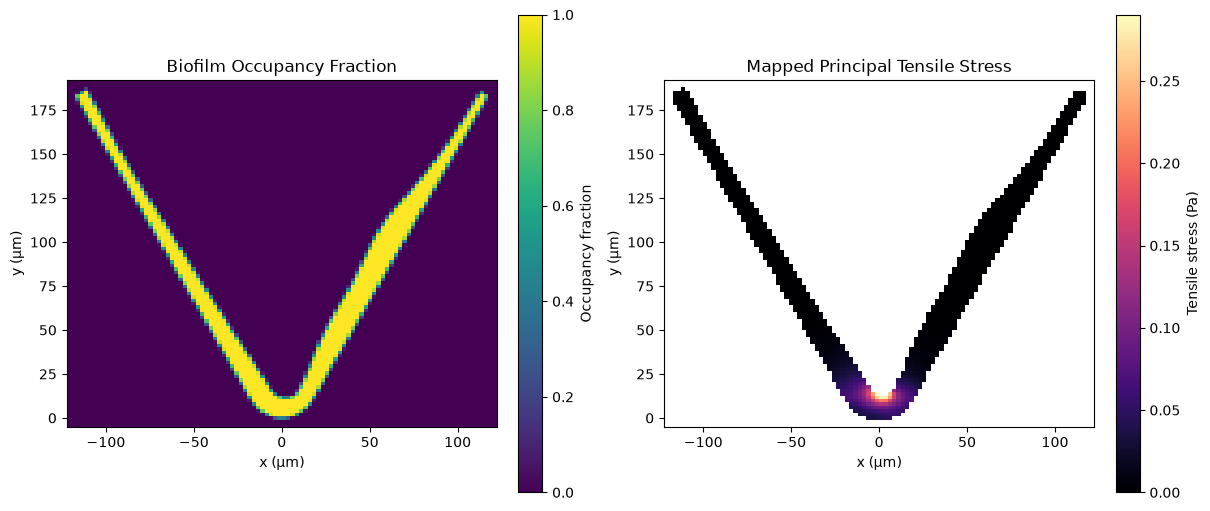

In [70]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    constrained_layout=True,
)

# Occupancy fraction
im0 = axes[0].imshow(
    grid_result["occupancy_fraction"],
    origin="lower",
    extent=[
        x_edges[0],
        x_edges[-1],
        y_edges[0],
        y_edges[-1],
    ],
    cmap="viridis",
    vmin=0,
    vmax=1,
    aspect="equal",
)

axes[0].set_title("Biofilm Occupancy Fraction")

fig.colorbar(
    im0,
    ax=axes[0],
    label="Occupancy fraction",
)

# Tensile stress
im1 = axes[1].imshow(
    grid_result["fields"]["tensile_stress"],
    origin="lower",
    extent=[
        x_edges[0],
        x_edges[-1],
        y_edges[0],
        y_edges[-1],
    ],
    cmap="magma",
    aspect="equal",
)

axes[1].set_title("Mapped Principal Tensile Stress")

fig.colorbar(
    im1,
    ax=axes[1],
    label="Tensile stress (Pa)",
)

for ax in axes:
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")

plt.show()

## 42. Verifying Interfacial Traction Calculations

### Objective

We calculate mechanical tractions transmitted across the
biofilm–bellows interface.

According to Cauchy's stress formula:

$$
\boxed{
\mathbf t=\boldsymbol{\sigma}\mathbf n
}
$$

The traction vector is decomposed into normal and tangential
components:

$$
\boxed{
t_n=\mathbf n^T\boldsymbol{\sigma}\mathbf n
}
$$

$$
\boxed{
t_s=\mathbf s^T\boldsymbol{\sigma}\mathbf n
}
$$

where $\mathbf n$ and $\mathbf s$ are the local unit normal
and tangent vectors.

### Physical interpretation

Positive normal traction indicates tensile loading across
the interface, whereas negative normal traction indicates
compression.

Tangential traction represents shear loading along the
interface.

These quantities provide indicators of potential adhesive
vulnerability, but do not establish actual debonding.

### Numerical approximation

Interfacial tractions are estimated using the stress tensor
of the triangular element adjacent to each substrate edge.

Because these are element-averaged stresses, the resulting
tractions are approximate and require mesh-convergence
verification.

In [71]:
import numpy as np

def decompose_traction(sigma, normal, tangent):
    traction = sigma @ normal

    tn = normal @ traction
    ts = tangent @ traction

    return tn, ts


# Test 1: Pure normal tension
sigma = np.array([
    [0.0, 0.0],
    [0.0, 10.0],
])

normal = np.array([0.0, 1.0])
tangent = np.array([1.0, 0.0])

tn, ts = decompose_traction(sigma, normal, tangent)

assert np.isclose(tn, 10.0)
assert np.isclose(ts, 0.0)


# Test 2: Pure normal compression
sigma = np.array([
    [0.0, 0.0],
    [0.0, -10.0],
])

tn, ts = decompose_traction(sigma, normal, tangent)

assert np.isclose(tn, -10.0)
assert np.isclose(ts, 0.0)


# Test 3: Pure shear
sigma = np.array([
    [0.0, 5.0],
    [5.0, 0.0],
])

tn, ts = decompose_traction(sigma, normal, tangent)

assert np.isclose(tn, 0.0)
assert np.isclose(ts, 5.0)

print("All analytical traction tests passed.")

All analytical traction tests passed.


## 43. Interfacial Traction Under Bellows Deformation

### Objective

We investigate whether hypothetical biofilm thickness reduction
changes the mechanical loading transmitted across the
biofilm–bellows interface.

Both biofilms experience identical prescribed bellows movement:

$$
60^\circ\rightarrow60.5^\circ
$$

The regulated biofilm retains 50% of the unregulated thickness.

### Adhesive vulnerability indicators

We calculate the tensile component of normal traction:

$$
\boxed{
t_n^+=\max(t_n,0)
}
$$

We also calculate the magnitude of interfacial shear traction:

$$
\boxed{
|t_s|
}
$$

These quantities distinguish tensile separation loading
from tangential shear loading.

They are not calibrated adhesion-failure criteria.

### Comparison

We compare:

1. Maximum tensile normal traction.
2. Maximum absolute shear traction.
3. Length-weighted mean tensile normal traction.
4. Length-weighted mean absolute shear traction.

The length-weighted quantities describe the average
mechanical loading along the curved interface.

In [72]:
from src.interface_traction import calculate_interface_traction

interface_results = {}

for condition, result in tensile_results.items():

    interface = calculate_interface_traction(
        points=result["points_um"],
        triangles=result["triangles"],
        stress=result["stress"],
        substrate_nodes=result["boundaries"]["substrate"],
    )

    interface_results[condition] = interface

    tn = interface["normal_traction"]
    ts = interface["shear_traction"]
    lengths = interface["lengths"]

    # Tensile normal traction only
    tn_positive = np.maximum(tn, 0.0)

    # Shear traction magnitude
    ts_absolute = np.abs(ts)

    print(f"\n=== {condition.upper()} ===")

    print(
        f"Maximum tensile normal traction: "
        f"{tn_positive.max():.6f} Pa"
    )

    print(
        f"Maximum shear traction: "
        f"{ts_absolute.max():.6f} Pa"
    )

    print(
        f"Mean tensile normal traction: "
        f"{np.average(tn_positive, weights=lengths):.6f} Pa"
    )

    print(
        f"Mean absolute shear traction: "
        f"{np.average(ts_absolute, weights=lengths):.6f} Pa"
    )


=== UNREGULATED ===
Maximum tensile normal traction: 0.044154 Pa
Maximum shear traction: 0.041849 Pa
Mean tensile normal traction: 0.005077 Pa
Mean absolute shear traction: 0.004841 Pa

=== REGULATED ===
Maximum tensile normal traction: 0.012854 Pa
Maximum shear traction: 0.021182 Pa
Mean tensile normal traction: 0.001175 Pa
Mean absolute shear traction: 0.001357 Pa


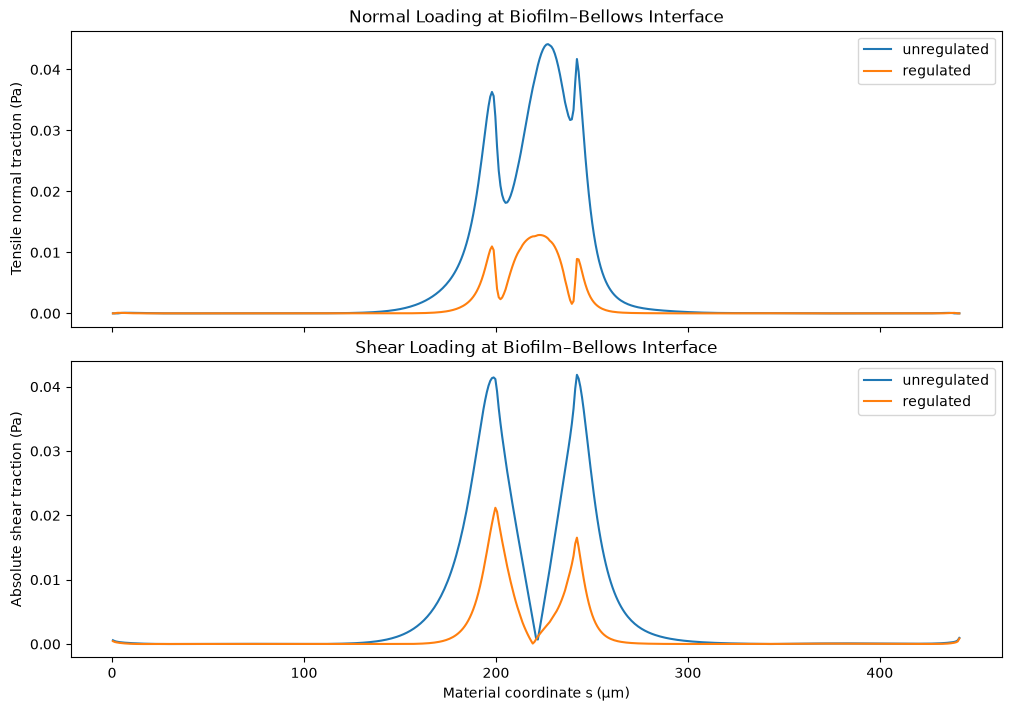

In [73]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True,
)

for condition, interface in interface_results.items():

    # Arc-length coordinate of segment midpoints
    lengths = interface["lengths"]

    s_edges = np.concatenate([
        [0.0],
        np.cumsum(lengths),
    ])

    s_mid = 0.5 * (
        s_edges[:-1] + s_edges[1:]
    )

    tn_positive = np.maximum(
        interface["normal_traction"],
        0.0,
    )

    ts_absolute = np.abs(
        interface["shear_traction"]
    )

    axes[0].plot(
        s_mid,
        tn_positive,
        label=condition,
    )

    axes[1].plot(
        s_mid,
        ts_absolute,
        label=condition,
    )

axes[0].set_ylabel("Tensile normal traction (Pa)")
axes[0].set_title("Normal Loading at Biofilm–Bellows Interface")
axes[0].legend()

axes[1].set_xlabel("Material coordinate s (μm)")
axes[1].set_ylabel("Absolute shear traction (Pa)")
axes[1].set_title("Shear Loading at Biofilm–Bellows Interface")
axes[1].legend()

plt.show()

In [74]:
def interface_metrics(interface):

    tn = np.maximum(
        interface["normal_traction"],
        0.0,
    )

    ts = np.abs(
        interface["shear_traction"]
    )

    lengths = interface["lengths"]

    return {
        "max_normal": tn.max(),
        "max_shear": ts.max(),
        "mean_normal": np.average(tn, weights=lengths),
        "mean_shear": np.average(ts, weights=lengths),
    }


u_metrics = interface_metrics(
    interface_results["unregulated"]
)

r_metrics = interface_metrics(
    interface_results["regulated"]
)

print("=== Effect of Thickness Regulation on Interface Loading ===")

for metric in u_metrics:

    u_value = u_metrics[metric]
    r_value = r_metrics[metric]

    if u_value > 0:
        reduction = 100 * (1 - r_value / u_value)

        print(
            f"{metric:15s} | "
            f"Reduction = {reduction:.2f}%"
        )

=== Effect of Thickness Regulation on Interface Loading ===
max_normal      | Reduction = 70.89%
max_shear       | Reduction = 49.39%
mean_normal     | Reduction = 76.86%
mean_shear      | Reduction = 71.96%


## 44. Interfacial Traction Convergence

### Objective

We verify that the calculated interfacial traction metrics are
sufficiently insensitive to mesh refinement.

Our interface traction calculation uses element-averaged stresses
from triangular elements adjacent to the substrate.

Consequently, local traction estimates may depend on mesh
resolution, particularly near geometric transitions.

### Traction decomposition

The traction vector is:

$$
\mathbf t=\boldsymbol{\sigma}\mathbf n
$$

Its tensile normal component is:

$$
t_n^+=\max(\mathbf n^T\boldsymbol{\sigma}\mathbf n,0)
$$

The absolute tangential component is:

$$
|t_s|=|\mathbf s^T\boldsymbol{\sigma}\mathbf n|
$$

### Convergence criterion

For a mechanical quantity $Q$, the relative difference between
the medium and fine meshes is:

$$
\boxed{
\delta_Q=
\frac{|Q_{\mathrm{fine}}-Q_{\mathrm{medium}}|}
{|Q_{\mathrm{fine}}|}
\times100\%
}
$$

We evaluate both maximum and length-weighted mean tractions.

Convergence of these quantities supports numerical reliability
but does not establish experimentally calibrated adhesion strength.

In [75]:
traction_convergence = []

resolutions = [
    (500, 15),
    (1000, 30),
]

for n_surface, ny_test in resolutions:

    s_test = np.linspace(
        s_uniform.min(),
        s_uniform.max(),
        n_surface,
    )

    # Preserve the same reference morphology
    h_test = np.interp(
        s_test,
        s_uniform,
        h_uniform,
    )

    # Interpolate substrate geometry
    substrate_test = np.column_stack([
        np.interp(
            s_test,
            s_uniform,
            crevice_initial_uniform[:, 0],
        ),
        np.interp(
            s_test,
            s_uniform,
            crevice_initial_uniform[:, 1],
        ),
    ])

    # Interpolate prescribed bellows displacement
    displacement_test = np.column_stack([
        np.interp(
            s_test,
            s_uniform,
            bellows_displacement[:, 0],
        ),
        np.interp(
            s_test,
            s_uniform,
            bellows_displacement[:, 1],
        ),
    ])

    for condition, thickness in {
        "unregulated": h_test,
        "regulated": 0.5 * h_test,
    }.items():

        points, triangles, boundaries = build_curved_layer_mesh(
            substrate_points=substrate_test,
            thickness=thickness,
            ny=ny_test,
            normal_side="left",
        )

        result = solve_curved_biofilm(
            points=points,
            triangles=triangles,
            boundaries=boundaries,
            substrate_displacement=displacement_test,
            E=64.0,
            nu=0.3,
        )

        interface = calculate_interface_traction(
            points=result["points_um"],
            triangles=result["triangles"],
            stress=result["stress"],
            substrate_nodes=result["boundaries"]["substrate"],
        )

        metrics = interface_metrics(interface)

        traction_convergence.append({
            "n_surface": n_surface,
            "ny": ny_test,
            "elements": len(triangles),
            "condition": condition,
            **metrics,
        })

        print(
            f"{condition:12s} | "
            f"Elements={len(triangles):6d} | "
            f"Max normal={metrics['max_normal']:.6f} Pa | "
            f"Max shear={metrics['max_shear']:.6f} Pa"
        )

traction_convergence_df = pd.DataFrame(
    traction_convergence
)

sfepy: updating variables...
sfepy: ...done
sfepy: setting up dof connectivities...
sfepy: ...done in 0.00 s
sfepy: matrix shape: (15000, 15000)
sfepy: assembling matrix graph...
sfepy: ...done in 0.01 s
sfepy: matrix structural nonzeros: 201768 (8.97e-02% fill)
sfepy: updating variables...
sfepy: ...done
sfepy: updating variables...
sfepy: ...done
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
sfepy: nls: iter: 0, residual: 1.332371e-03 (rel: 1.000000e+00)
sfepy:   residual:    0.01 [s]
sfepy:     matrix:    0.00 [s]
sfepy:      solve:    0.01 [s]
sfepy: nls: iter: 1, residual: 3.400313e-18 (rel: 2.552075e-15)
sfepy: solved in 1 steps in 0.03 seconds
sfepy: equation "tmp":
sfepy: ev_cauchy_strain.i.Omega(u)
sfepy: updating materials...
sfepy: ...done in 0.00 s
sfepy: equation "tmp":
sfepy: ev_cauchy_stress.i.Omega(biofilm.D, u)
sfepy: updating materials...
sfepy:     biofilm
sfepy: ...done in 0.00 s
unregulated  | Elements= 14970 | Max normal=0.044154 Pa | Ma

In [76]:
metrics = [
    "max_normal",
    "max_shear",
    "mean_normal",
    "mean_shear",
]

print("=== Interfacial Traction Convergence ===")

for condition in ["unregulated", "regulated"]:

    subset = traction_convergence_df[
        traction_convergence_df["condition"] == condition
    ].sort_values("elements")

    print(f"\n{condition.upper()}")

    for metric in metrics:

        values = subset[metric].to_numpy()

        relative_error = (
            abs(values[1] - values[0])
            / abs(values[1])
        ) * 100

        print(
            f"{metric:15s} | "
            f"Relative difference = {relative_error:.4f}%"
        )

comparison = traction_convergence_df.pivot(
    index="elements",
    columns="condition",
    values=metrics,
)

print("\n === Convergence of Thickness-Regulation Effects ===")

for metric in metrics:

    u = comparison[metric]["unregulated"]
    r = comparison[metric]["regulated"]

    reduction = 100 * (1 - r / u)

    print(f"\n{metric}")

    for elements, value in reduction.items():
        print(
            f"{elements:6d} triangles | "
            f"Reduction = {value:.3f}%"
        )

=== Interfacial Traction Convergence ===

UNREGULATED
max_normal      | Relative difference = 1.4183%
max_shear       | Relative difference = 0.1776%
mean_normal     | Relative difference = 1.9864%
mean_shear      | Relative difference = 0.0230%

REGULATED
max_normal      | Relative difference = 5.0907%
max_shear       | Relative difference = 3.4394%
mean_normal     | Relative difference = 5.2988%
mean_shear      | Relative difference = 0.9971%

 === Convergence of Thickness-Regulation Effects ===

max_normal
 14970 triangles | Reduction = 70.889%
 59940 triangles | Reduction = 69.763%

max_shear
 14970 triangles | Reduction = 49.385%
 59940 triangles | Reduction = 50.981%

mean_normal
 14970 triangles | Reduction = 76.862%
 59940 triangles | Reduction = 76.052%

mean_shear
 14970 triangles | Reduction = 71.961%
 59940 triangles | Reduction = 71.685%


## 45. Picioreanu-Inspired Cohesive Failure Analysis

### Objective

We extend our structural FEM analysis using a cohesive failure
criterion inspired by Picioreanu et al. (2001), *Two-Dimensional
Model of Biofilm Detachment Caused by Internal Stress from Liquid Flow*.

The authors proposed that biofilm failure occurs when the
equivalent stress exceeds an assumed cohesion strength.

### Failure criterion

We define the dimensionless failure index:

$$
\boxed{
FI_k=\frac{\sigma_{e,k}}{\sigma_c}
}
$$

where:

- $\sigma_{e,k}$ is the von Mises equivalent stress in element $k$.
- $\sigma_c$ is the assumed biofilm cohesion strength.

The threshold-exceedance condition is:

$$
\boxed{
FI_k>1
}
$$

### Overstressed-area fraction

We quantify the proportion of biofilm area exceeding the
assumed cohesion strength:

$$
\boxed{
f_{\mathrm{over}}=
\frac{
\sum_k A_k\mathbb{1}(\sigma_{e,k}>\sigma_c)
}{
\sum_k A_k
}
}
$$

where $A_k$ is the area of triangular element $k$.

### Scientific limitations

Unlike Picioreanu et al., we do not remove failed elements,
recalculate mechanical equilibrium, or simulate fragmentation.

Our model also considers prescribed bellows deformation
rather than fluid-flow-induced loading.

Consequently, threshold exceedance represents a hypothetical
cohesive vulnerability indicator, not predicted biofilm
fracture or detachment.

Furthermore, our equivalent-stress calculation includes
the out-of-plane stress contribution under plane strain.

Reference:

Picioreanu, C., van Loosdrecht, M. C. M., & Heijnen, J. J.
(2001). Two-Dimensional Model of Biofilm Detachment Caused
by Internal Stress from Liquid Flow.
Biotechnology and Bioengineering, 72(2), 205–218.

In [78]:
import numpy as np

def cohesive_failure_metrics(result, strength):
    """
    Calculate Picioreanu-inspired cohesive vulnerability metrics.

    Parameters
    ----------
    result : dict
        Output from solve_curved_biofilm().

    strength : float
        Assumed cohesion strength in Pa.

    Returns
    -------
    dict
        Element failure indices, threshold mask,
        and area-weighted overstressed fraction.
    """

    if strength <= 0:
        raise ValueError("Cohesion strength must be positive.")

    stress = np.asarray(result["sigma_e"], dtype=float)
    areas = np.asarray(result["areas"], dtype=float)

    failure_index = stress / strength

    overstressed = failure_index > 1.0

    area_fraction = (
        np.sum(areas[overstressed])
        / np.sum(areas)
    )

    return {
        "failure_index": failure_index,
        "overstressed": overstressed,
        "area_fraction": float(area_fraction),
        "max_failure_index": float(failure_index.max()),
    }

unregulated  | Maximum FI = 2.694 | Overstressed area = 1.78%
regulated    | Maximum FI = 1.063 | Overstressed area = 0.11%


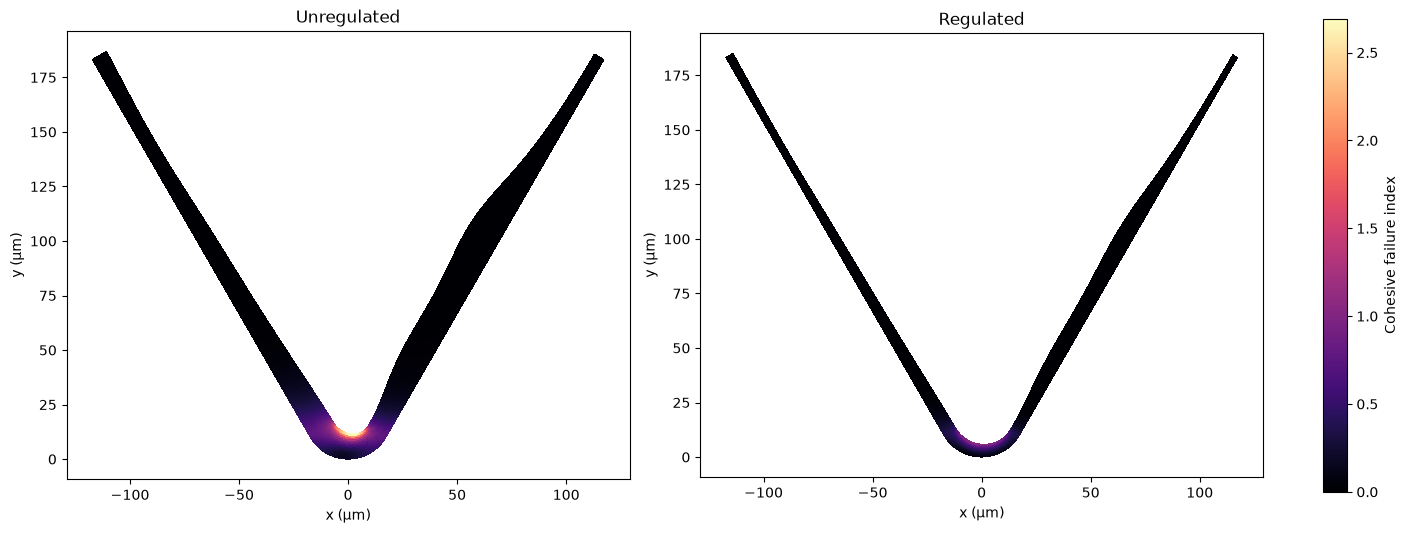

In [79]:
import matplotlib.pyplot as plt

STRENGTH = 0.1

failure_results = {}

for condition, result in tensile_results.items():

    failure = cohesive_failure_metrics(
        result,
        strength=STRENGTH,
    )

    failure_results[condition] = failure

    print(
        f"{condition:12s} | "
        f"Maximum FI = {failure['max_failure_index']:.3f} | "
        f"Overstressed area = {failure['area_fraction'] * 100:.2f}%"
    )


fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True,
)

vmax = max(
    f["failure_index"].max()
    for f in failure_results.values()
)

for ax, (condition, result) in zip(
    axes,
    tensile_results.items(),
):

    failure = failure_results[condition]

    points = result["points_um"]

    plot = ax.tripcolor(
        points[:, 0],
        points[:, 1],
        result["triangles"],
        facecolors=failure["failure_index"],
        shading="flat",
        cmap="magma",
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(condition.capitalize())
    ax.set_xlabel("x (μm)")
    ax.set_ylabel("y (μm)")
    ax.set_aspect("equal")

fig.colorbar(
    plot,
    ax=axes,
    label="Cohesive failure index",
    shrink=0.8,
)

plt.show()

## 46. Sensitivity to Assumed Biofilm Cohesion Strength

The cohesion strength of our engineered biofilm has not
been experimentally characterized.

We therefore investigate a range of hypothetical cohesion
strengths:

$$
\sigma_c\in[0.01,1.0]\ \mathrm{Pa}
$$

For each strength, we calculate the area-weighted fraction
of biofilm exceeding the equivalent-stress threshold.

This allows us to compare the mechanical vulnerability of
baseline and reduced-thickness biofilms without assuming
a single experimentally validated failure strength.

The lower end of this range is exploratory and should not
be interpreted as a measured cohesion strength.

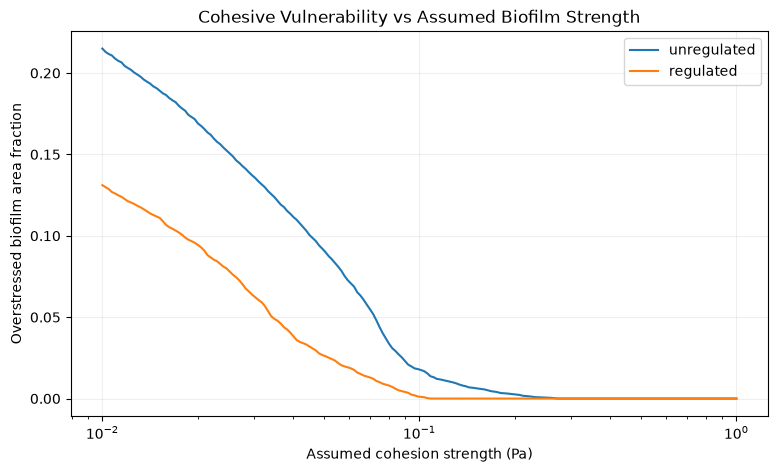

In [80]:
strength_values = np.geomspace(
    0.01,
    1.0,
    200,
)

vulnerability_curves = {}

for condition, result in tensile_results.items():

    fractions = []

    for strength in strength_values:

        failure = cohesive_failure_metrics(
            result,
            strength=strength,
        )

        fractions.append(
            failure["area_fraction"]
        )

    vulnerability_curves[condition] = np.asarray(fractions)


plt.figure(figsize=(9, 5))

for condition, fractions in vulnerability_curves.items():

    plt.plot(
        strength_values,
        fractions,
        label=condition,
    )

plt.xscale("log")

plt.xlabel("Assumed cohesion strength (Pa)")
plt.ylabel("Overstressed biofilm area fraction")

plt.title(
    "Cohesive Vulnerability vs Assumed Biofilm Strength"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## 47. Strength-Retention Sensitivity

Biofilm regulation may alter extracellular matrix composition,
potentially affecting both biofilm geometry and mechanical strength.

We therefore introduce a hypothetical strength-retention factor:

$$
\boxed{
\beta=
\frac{\sigma_{c,\mathrm{reduced}}}
{\sigma_{c,\mathrm{baseline}}}
}
$$

Thus:

$$
\sigma_{c,\mathrm{reduced}}
=
\beta\sigma_{c,\mathrm{baseline}}
$$

We compare the overstressed-area fractions:

$$
\Delta f_{\mathrm{over}}
=
f_{\mathrm{over,reduced}}
-
f_{\mathrm{over,baseline}}
$$

Interpretation:

- $\Delta f_{\mathrm{over}}<0$: Reduced-thickness biofilm has a smaller overstressed-area fraction.
- $\Delta f_{\mathrm{over}}>0$: Reduced-thickness biofilm has a larger overstressed-area fraction.
- $\Delta f_{\mathrm{over}}=0$: Both have equal overstressed-area fractions.

This analysis investigates whether the mechanical benefits
of thinning persist when cohesion strength also decreases.

It does not establish a quantitative relationship between
gene expression and biofilm strength.

In [81]:
baseline_strengths = np.linspace(
    0.01,
    0.35,
    120,
)

beta_values = np.linspace(
    0.2,
    1.2,
    100,
)

u = tensile_results["unregulated"]
r = tensile_results["regulated"]

# Stress arrays
sigma_u = u["sigma_e"]
sigma_r = r["sigma_e"]

# Normalize element areas into weights
weights_u = u["areas"] / u["areas"].sum()
weights_r = r["areas"] / r["areas"].sum()

# Baseline overstressed-area fraction
fraction_u = np.sum(
    weights_u[:, None]
    * (
        sigma_u[:, None]
        > baseline_strengths[None, :]
    ),
    axis=0,
)

# Reduced-thickness overstressed-area fraction
fraction_r = np.zeros(
    (len(beta_values), len(baseline_strengths))
)

for i, beta in enumerate(beta_values):

    thresholds = beta * baseline_strengths

    fraction_r[i] = np.sum(
        weights_r[:, None]
        * (
            sigma_r[:, None]
            > thresholds[None, :]
        ),
        axis=0,
    )

# Difference: reduced thickness minus baseline
delta_fraction = (
    fraction_r - fraction_u[None, :]
)

print("Strength-retention analysis completed.")

Strength-retention analysis completed.


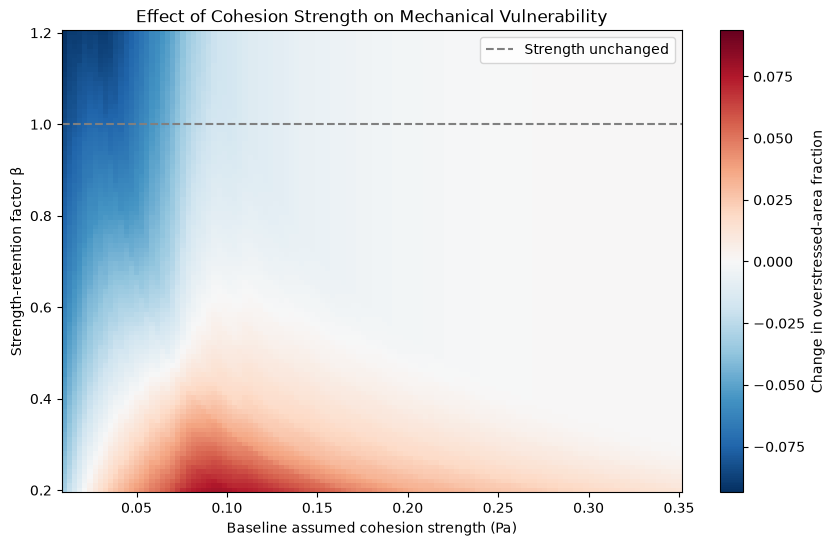

In [82]:
fig, ax = plt.subplots(figsize=(10, 6))

limit = np.max(np.abs(delta_fraction))

im = ax.pcolormesh(
    baseline_strengths,
    beta_values,
    delta_fraction,
    shading="auto",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
)

fig.colorbar(
    im,
    ax=ax,
    label="Change in overstressed-area fraction",
)

ax.axhline(
    1.0,
    color="gray",
    linestyle="--",
    label="Strength unchanged",
)

ax.set_xlabel(
    "Baseline assumed cohesion strength (Pa)"
)

ax.set_ylabel(
    "Strength-retention factor β"
)

ax.set_title(
    "Effect of Cohesion Strength on Mechanical Vulnerability"
)

ax.legend()

plt.show()

In [83]:
# Construct a simple synthetic FEM result
test_result = {
    "sigma_e": np.array([0.05, 0.10, 0.20]),
    "areas": np.array([1.0, 2.0, 3.0]),
}

# Threshold = 0.15 Pa
test = cohesive_failure_metrics(
    test_result,
    strength=0.15,
)

# Only the third element exceeds the threshold
assert np.array_equal(
    test["overstressed"],
    [False, False, True],
)

# Overstressed area = 3 / 6
assert np.isclose(
    test["area_fraction"],
    0.5,
)

# Very high strength -> no overstressed elements
high_strength = cohesive_failure_metrics(
    test_result,
    strength=10.0,
)

assert high_strength["area_fraction"] == 0.0

# Very low strength -> all elements overstressed
low_strength = cohesive_failure_metrics(
    test_result,
    strength=0.001,
)

assert low_strength["area_fraction"] == 1.0

print("Cohesive failure-index verification passed.")

Cohesive failure-index verification passed.
